# ReturnRoute：AI 需求预测模块（完整流程）

本文件包含 ReturnRoute 需求预测模型从数据探索到最终预测的全部步骤，按顺序从上到下运行即可（全部运行约 5 分钟）。

| 阶段 | 内容 | 要回答的问题 |
|---|---|---|
| **第一阶段** | EDA（探索性数据分析） | 销量到底有什么规律？ |
| **第二阶段** | Feature Engineering（特征工程） | 怎样把“昨天、上周、季节”变成模型能用的变量？ |
| **第三阶段** | Baseline（基准模型） | 不用 AI 的简单规则能做到多准？ |
| **第四阶段** | 训练 Random Forest | 用哪些特征训练模型？ |
| **第五阶段** | Evaluation（模型评估） | AI 比简单规则准多少？ |
| **第六阶段** | Actual vs Predicted | AI 有没有真正学到需求的变化？ |
| **第七阶段** | Hyperparameter Tuning（调参） | 换几组合理的参数，会不会更准？ |
| **第八阶段** | Feature Importance（特征重要性） | 模型主要依靠哪些信息？ |
| **第九阶段** | Final model fitting（最终训练） | 用全部数据训练，预测 2018 年第一周 |
| **第十阶段** | AI 模型到此结束 | AI、系统规则和员工分别负责什么？ |

- **数据**：Kaggle *Store Item Demand Forecasting Challenge* 的 `train.csv`，包含 2013–2017 年 10 家店 × 50 个商品的每日销量。
- **预测目标**：在日期 d 的早上，只用 d-1 及以前的数据，预测某商品在某门店 **d 到 d+6 这 7 天的销量总和**。
- **门店对应关系**：Presentation 里的 Store A / B / C 对应数据中的 Store 1 / 2 / 3。
- **图表**：图中文字使用英文，方便直接放进英文 PPT。所有图会自动保存到 `figures/` 文件夹。

## 0.1 准备工作：导入库并统一设置

这段代码是整个文件唯一的设置部分，后面所有阶段都会用到这里定义的内容：
- 导入数据分析（pandas、numpy）、画图（matplotlib）和机器学习（scikit-learn 的 `RandomForestRegressor`）需要的库；
- 设置数据文件路径和输出文件夹（`figures/` 保存图片，`outputs/` 保存最终预测）；
- 定义全局常量：随机种子、示例序列、特征名单、预测窗口长度等；
- 定义两个小函数：`save()` 保存图片；`evaluate()` 计算 MAE、RMSE、WAPE 和 Bias 四个误差指标。所有模型都用同一个函数评估，保证比较口径一致。

> 如果数据文件不在默认位置，只需要修改 `DATA_PATH`。

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor

# ---- Paths: change DATA_PATH if your train.csv is stored elsewhere ----
DATA_PATH = Path("../Data set/demand-forecasting-kernels-only/train.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
SEED = 42

# ---- Example series and presentation labels ----
EXAMPLE_STORE, EXAMPLE_ITEM = 1, 1
STORE_NAME = {1: "A", 2: "B", 3: "C"}          # Store A / B / C in the slides = dataset store 1 / 2 / 3
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# ---- Feature engineering settings ----
LAGS = [1, 7, 14, 28]          # lag_k = sales k days before date d
WINDOWS = [7, 14, 28]          # rolling_k = average sales over the k days before d
HORIZON = 7                    # target = total sales over d ... d+6
LAST_YEAR = 364                # 52 weeks: same weekday one year earlier
BASE_FEATURES = (["store", "item", "year", "month", "day_of_week", "day_of_month",
                  "week_of_year", "is_weekend"]
                 + [f"lag_{k}" for k in LAGS]
                 + [f"rolling_{w}" for w in WINDOWS])
EXTRA_FEATURES = ["last_year_7d_sum", "yoy_ratio_28"]
TARGET = "target_7d"

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    """Save a figure into figures/ as a high-resolution PNG for the slides."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def evaluate(y_true, y_pred):
    """Return MAE, RMSE, WAPE (%) and Bias for one set of predictions."""
    err = np.asarray(y_pred) - np.asarray(y_true)
    return pd.Series({"MAE": np.mean(np.abs(err)),
                      "RMSE": np.sqrt(np.mean(err ** 2)),
                      "WAPE %": np.sum(np.abs(err)) / np.sum(y_true) * 100,
                      "Bias": np.mean(err)})

print("Data file found:", DATA_PATH.exists())

Data file found: True


## 0.2 读取数据

这段代码会：
- 读取 `train.csv`，把 `date` 转成日期格式；
- **按“门店 → 商品 → 日期”排序**。后面所有“前 k 天”“未来 7 天”的计算，都是在同一条“门店 × 商品”序列内部按时间移动的，所以排序必须正确；
- 从日期里拆出 `year`（年）、`month`（月）和 `dow`（星期几，0 = 周一 … 6 = 周日），EDA 要用；
- 确认每条序列都是连续、完整的日期。如果中间缺了某天，“往前移 7 行”就不等于“往前 7 天”；
- 显示数据的行列数和前 5 行。

数据只有 4 个原始字段：`date`（日期）、`store`（门店编号 1–10）、`item`（商品编号 1–50）、`sales`（当天销量）。

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["dow"] = df["date"].dt.dayofweek   # 0 = Monday ... 6 = Sunday

n_days = df["date"].nunique()
assert (df.groupby(["store", "item"]).size() == n_days).all(), "Some series have missing dates!"
assert (df.groupby(["store", "item"])["date"].diff().dropna() == pd.Timedelta(days=1)).all()
print("Shape:", df.shape, "| every series is complete and continuous:", n_days, "days")
df.head()

Shape: (913000, 7) | every series is complete and continuous: 1826 days


,date,store,item,sales,year,month,dow
0,2013-01-01,1,1,13,2013,1,1
1,2013-01-02,1,1,11,2013,1,2
2,2013-01-03,1,1,14,2013,1,3
3,2013-01-04,1,1,13,2013,1,4
4,2013-01-05,1,1,10,2013,1,5


---
# 第一阶段：EDA（探索性数据分析）

**EDA = Exploratory Data Analysis。** 这一阶段不是为了画很多图，而是回答一个问题：

> **销量到底有什么规律？**

对 ReturnRoute 来说，最需要弄清楚的是下面 4 件事。它们会直接决定后面的 Feature Engineering（特征工程）怎么做：

| 问题 | 要回答什么 |
|---|---|
| **Weekly pattern** | 星期六是不是比星期一卖得多？ |
| **Monthly / seasonal pattern** | 夏天和冬天的销量有没有明显不同？ |
| **Trend** | 销量是不是逐年增长？ |
| **Store difference** | 同一个商品，Store 1 和 Store 3 的销售水平是不是完全不同？ |

## 1.1 数据质量检查

分析规律之前，先确认数据本身是否可靠。这段代码会检查：
- 数据覆盖的时间范围和天数；
- 有几家店、几个商品，一共多少条“门店 × 商品”序列；
- **每条序列是否都有完整的每一天**（如果缺日期，后面算“过去 7 天”“未来 7 天”时就会出错）；
- 是否有缺失值、重复行、销量为 0 的天数；
- 销量的基本统计量（平均值、标准差、最小值、四分位数、最大值）。

In [3]:
all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
rows_per_series = df.groupby(["store", "item"]).size()

quality = pd.Series({
    "Start date": df["date"].min().date(),
    "End date": df["date"].max().date(),
    "Number of days": len(all_days),
    "Stores": df["store"].nunique(),
    "Items": df["item"].nunique(),
    "Series (store x item)": len(rows_per_series),
    "Every series has every day": bool((rows_per_series == len(all_days)).all()),
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate (date, store, item) rows": int(df.duplicated(["date", "store", "item"]).sum()),
    "Days with zero sales": int((df["sales"] == 0).sum()),
})
display(quality.to_frame("value"))
display(df["sales"].describe().to_frame("daily sales").T)

,value
Start date,2013-01-01
End date,2017-12-31
Number of days,1826
Stores,10
Items,50
Series (store x item),500
Every series has every day,True
Missing values,0
"Duplicate (date, store, item) rows",0
Days with zero sales,1


,count,mean,std,min,25%,50%,75%,max
daily sales,"913,000.00",52.25,28.80,0.00,30.00,47.00,70.00,231.00


## 1.2 先看一条序列：Store 1 × Item 1（2013–2017）

这段代码会画两张图：
- **上图**：整整 5 年的每日销量（浅色细线），再叠加 30 天滑动平均（深色粗线）。滑动平均能过滤掉每天的随机波动，更容易看出**季节起伏**和**逐年上升的趋势**；
- **下图**：只放大 2017 年 6 月一个月，看在更短的时间尺度上是否有**按星期重复的锯齿形波动**（周末高、周一低）。

看图时请留意三件事：每年是否在同样的月份出现高峰？整体是否一年比一年高？一个月里是否每 7 天重复一次起伏？

> 单条序列每天的随机波动很大，下图的周规律并不明显。所以 1.3 节会用**全部 500 条序列**的平均值，把周规律准确地算出来。

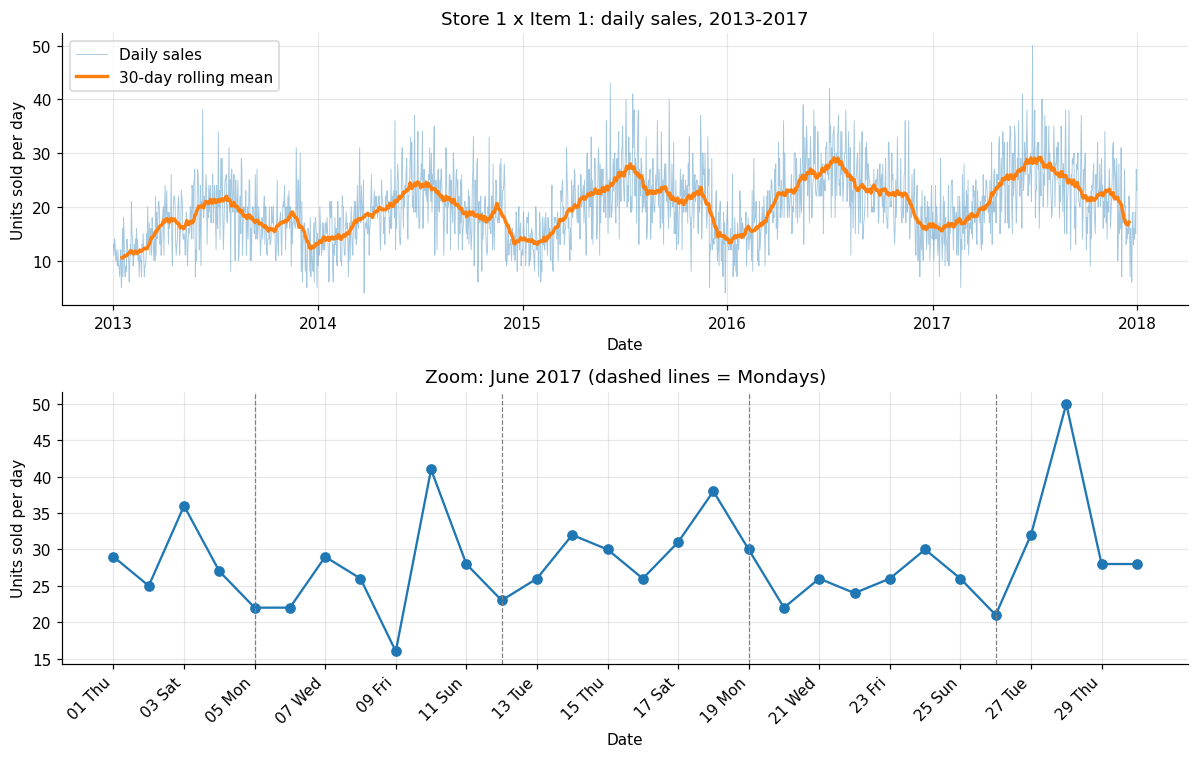

In [4]:
ex = (df[(df["store"] == EXAMPLE_STORE) & (df["item"] == EXAMPLE_ITEM)]
      .set_index("date")["sales"])

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ax = axes[0]
ax.plot(ex.index, ex.values, lw=0.6, alpha=0.4, label="Daily sales")
ax.plot(ex.rolling(30, center=True).mean(), lw=2.2, label="30-day rolling mean")
ax.set(title=f"Store {EXAMPLE_STORE} x Item {EXAMPLE_ITEM}: daily sales, 2013-2017",
       xlabel="Date", ylabel="Units sold per day")
ax.legend(loc="upper left")

ax = axes[1]
month_view = ex.loc["2017-06-01":"2017-06-30"]
ax.plot(month_view.index, month_view.values, marker="o", lw=1.5)
for d in month_view.index[month_view.index.dayofweek == 0]:      # mark Mondays
    ax.axvline(d, color="grey", ls="--", lw=0.8)
ax.set_xticks(month_view.index[::2])
ax.set_xticklabels(month_view.index[::2].strftime("%d %a"), rotation=45, ha="right")
ax.set(title="Zoom: June 2017 (dashed lines = Mondays)",
       xlabel="Date", ylabel="Units sold per day")

fig.tight_layout()
save(fig, "eda_1_example_series")
plt.show()

## 1.3 Weekly pattern：星期六是不是比星期一卖得多？

这段代码会：
- 用**全部数据**算出“星期几指数”：某个星期几的平均销量 ÷ 所有天的平均销量。指数 1.10 表示比平均水平高 10%；
- **左图**：7 天的指数柱状图；
- **右图**：把 10 家店的星期规律分别画成 10 条线，检查**不同门店的周规律是否一样**；
- 打印星期六与星期一的销量之比，以及各门店之间周规律的最大差异。

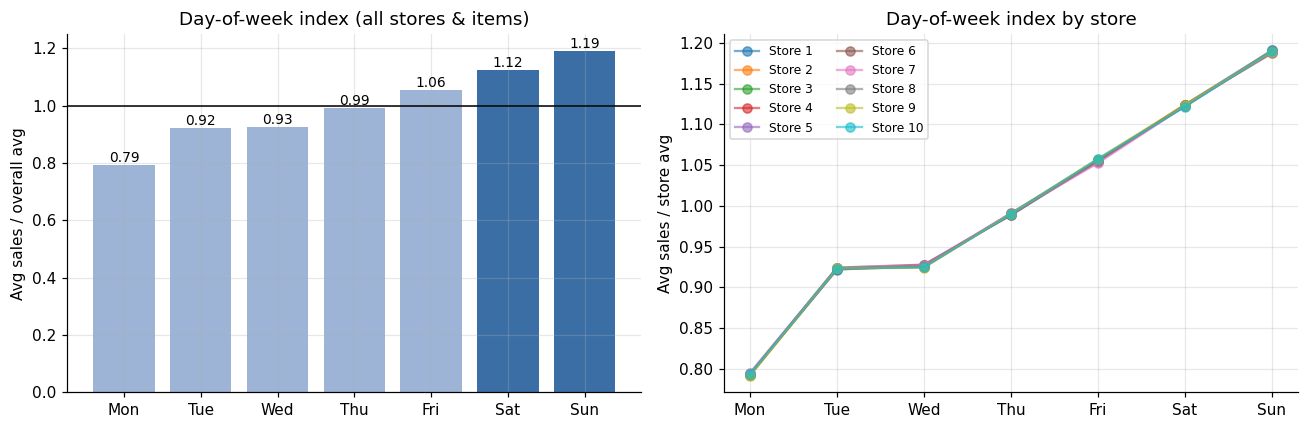

Saturday / Monday sales ratio: 1.42
Highest day: Sun (1.19), lowest day: Mon (0.79)
Largest difference between stores in any weekday index: 0.0017


In [5]:
dow_index = df.groupby("dow")["sales"].mean() / df["sales"].mean()

store_dow = df.groupby(["store", "dow"])["sales"].mean().unstack()
store_dow = store_dow.div(store_dow.mean(axis=1), axis=0)   # each store relative to its own average

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
bars = ax.bar(DOW_NAMES, dow_index.values, color=["#9db4d6"] * 5 + ["#3a6ea5"] * 2)
ax.axhline(1, color="black", lw=1)
ax.bar_label(bars, fmt="%.2f", fontsize=9)
ax.set(title="Day-of-week index (all stores & items)", ylabel="Avg sales / overall avg")

ax = axes[1]
for store, row in store_dow.iterrows():
    ax.plot(DOW_NAMES, row.values, marker="o", alpha=0.6, label=f"Store {store}")
ax.set(title="Day-of-week index by store", ylabel="Avg sales / store avg")
ax.legend(ncol=2, fontsize=8)

fig.tight_layout()
save(fig, "eda_2_weekly_pattern")
plt.show()

print(f"Saturday / Monday sales ratio: {dow_index[5] / dow_index[0]:.2f}")
print(f"Highest day: {DOW_NAMES[dow_index.idxmax()]} ({dow_index.max():.2f}), "
      f"lowest day: {DOW_NAMES[dow_index.idxmin()]} ({dow_index.min():.2f})")
print(f"Largest difference between stores in any weekday index: {store_dow.std().max():.4f}")

## 1.4 Monthly / seasonal pattern：夏天和冬天的销量有没有明显不同？

这段代码会：
- 算出“月份指数”：某个月的平均日销量 ÷ 全年平均日销量；
- **左图**：12 个月的指数柱状图；
- **右图**：把 2013–2017 每一年的月平均日销量各画成一条线（季节图）。如果 5 条线形状相同、只是上下平移，说明**季节规律每年重复**；
- 打印夏季（6–8 月）与冬季（12–2 月）的销量之比；
- 检查 50 个商品的季节规律是否一样。

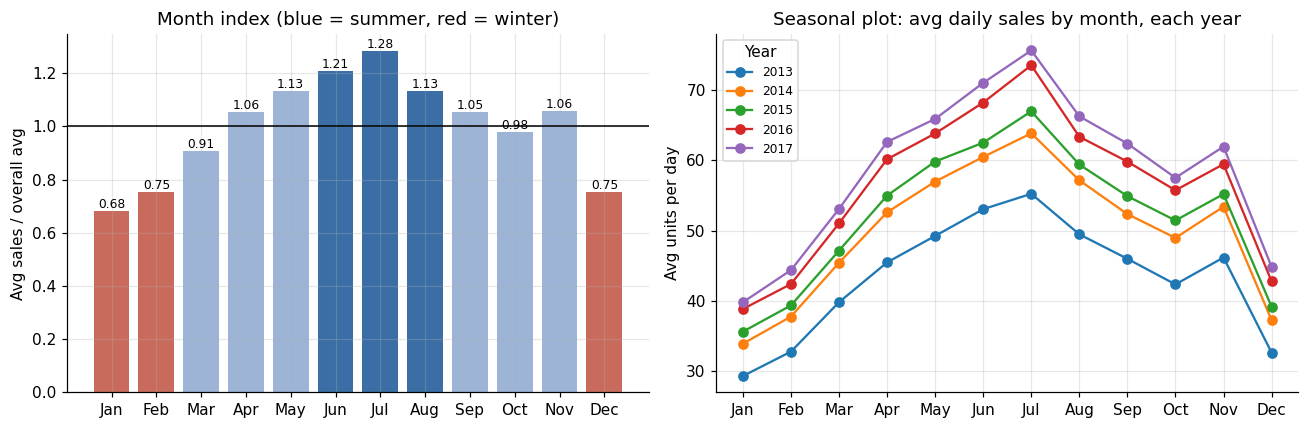

Summer (Jun-Aug) index: 1.21 | Winter (Dec-Feb) index: 0.73 | Summer / Winter = 1.66
Peak month: Jul (1.28), lowest month: Jan (0.68)
Largest difference between items in any month index: 0.0052


In [6]:
month_index = df.groupby("month")["sales"].mean() / df["sales"].mean()
year_month = df.groupby(["year", "month"])["sales"].mean().unstack(0)   # rows = month, columns = year

item_month = df.groupby(["item", "month"])["sales"].mean().unstack()
item_month = item_month.div(item_month.mean(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
colors = ["#3a6ea5" if m in (6, 7, 8) else "#9db4d6" if m not in (12, 1, 2) else "#c96b5c"
          for m in month_index.index]
bars = ax.bar(MONTH_NAMES, month_index.values, color=colors)
ax.axhline(1, color="black", lw=1)
ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set(title="Month index (blue = summer, red = winter)", ylabel="Avg sales / overall avg")

ax = axes[1]
for year in year_month.columns:
    ax.plot(MONTH_NAMES, year_month[year].values, marker="o", label=str(year))
ax.set(title="Seasonal plot: avg daily sales by month, each year", ylabel="Avg units per day")
ax.legend(title="Year", fontsize=8)

fig.tight_layout()
save(fig, "eda_3_seasonal_pattern")
plt.show()

summer = month_index.loc[[6, 7, 8]].mean()
winter = month_index.loc[[12, 1, 2]].mean()
print(f"Summer (Jun-Aug) index: {summer:.2f} | Winter (Dec-Feb) index: {winter:.2f} | "
      f"Summer / Winter = {summer / winter:.2f}")
print(f"Peak month: {MONTH_NAMES[month_index.idxmax() - 1]} ({month_index.max():.2f}), "
      f"lowest month: {MONTH_NAMES[month_index.idxmin() - 1]} ({month_index.min():.2f})")
print(f"Largest difference between items in any month index: {item_month.std().max():.4f}")

## 1.5 Trend：销量是不是逐年增长？

这段代码会：
- 汇总每年的总销量，算出**同比增长率**，以及以 2013 年为 1 的**增长指数**；
- **左图**：每月总销量，叠加 12 个月滑动平均。12 个月平均正好抵消季节起伏，剩下的就是长期趋势；
- **右图**：每家店各自的增长指数，检查**各门店是否以相同速度增长**。

,Total units,YoY growth %,Index (2013 = 1)
year,,,
2013,7941243,NaN,1.00
2014,9135482,15.04,1.15
2015,9536887,4.39,1.20
2016,10357160,8.60,1.30
2017,10733740,3.64,1.35


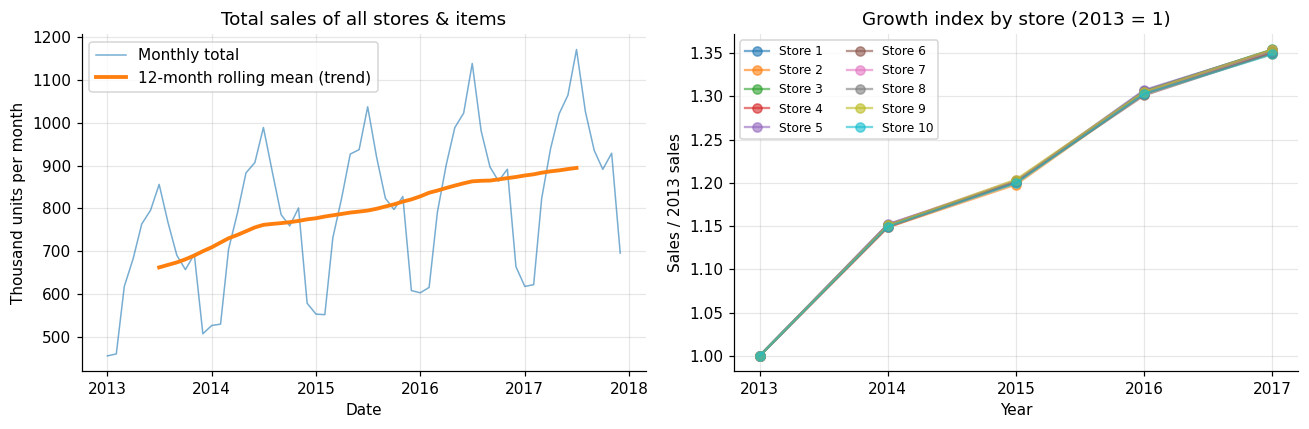

2017 growth index by store: min 1.349, max 1.354


In [7]:
yearly = df.groupby("year")["sales"].sum()
trend_table = pd.DataFrame({
    "Total units": yearly,
    "YoY growth %": yearly.pct_change() * 100,
    "Index (2013 = 1)": yearly / yearly.iloc[0],
})
display(trend_table)

monthly_total = df.set_index("date")["sales"].resample("MS").sum()
store_year = df.groupby(["year", "store"])["sales"].sum().unstack()
store_growth = store_year / store_year.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(monthly_total.index, monthly_total.values / 1e3, lw=1, alpha=0.6, label="Monthly total")
ax.plot(monthly_total.rolling(12, center=True).mean() / 1e3, lw=2.5, label="12-month rolling mean (trend)")
ax.set(title="Total sales of all stores & items", xlabel="Date", ylabel="Thousand units per month")
ax.legend(loc="upper left")

ax = axes[1]
for store in store_growth.columns:
    ax.plot(store_growth.index, store_growth[store].values, marker="o", alpha=0.6, label=f"Store {store}")
ax.set(title="Growth index by store (2013 = 1)", xlabel="Year", ylabel="Sales / 2013 sales")
ax.set_xticks(store_growth.index)
ax.legend(ncol=2, fontsize=8)

fig.tight_layout()
save(fig, "eda_4_trend")
plt.show()

print("2017 growth index by store: "
      f"min {store_growth.iloc[-1].min():.3f}, max {store_growth.iloc[-1].max():.3f}")

## 1.6 Store difference：同一个商品，Store 1 和 Store 3 的销售水平是不是完全不同？

这段代码分两步：

**(a) 看同一个商品（Item 1）在各家店的销量**
- **左图**：Item 1 在 10 家店的平均日销量；
- **右图**：Item 1 在 Store 1 和 Store 3 的**每周销量**走势对比；
- 打印 Store 3 与 Store 1 的销量之比，以及两条周销量曲线的相关系数。相关系数接近 1，说明两家店“一起涨、一起跌”，差别主要在销量的高低。

**(b) 看这种门店差异是否对所有商品都一样**
- 对每个商品，算出每家店占该商品总销量的比例（门店份额）；
- 箱线图里，每个箱子代表一家店在 50 个商品上的份额分布。箱子越扁，说明**这家店对所有商品的份额几乎相同**。

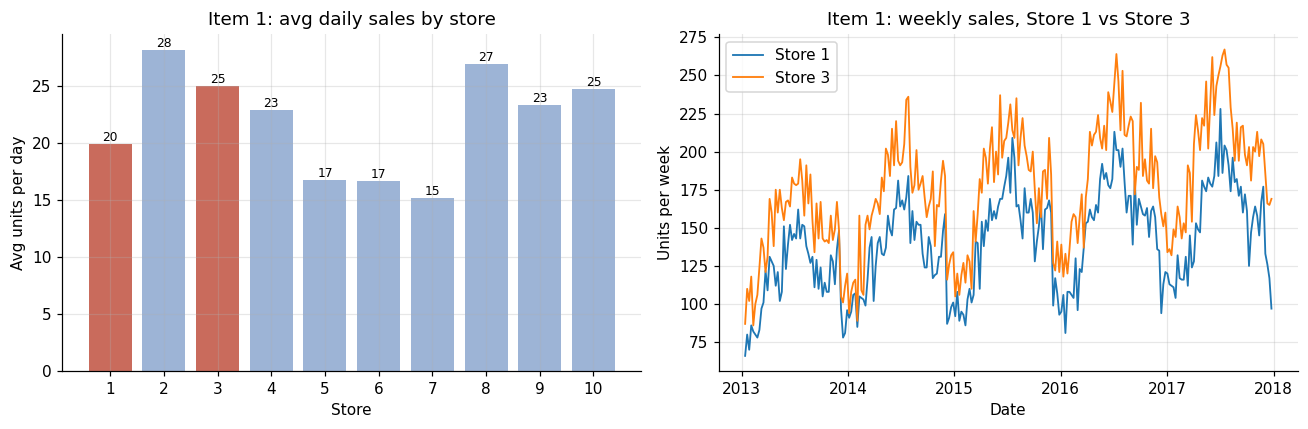

Item 1: Store 3 / Store 1 sales ratio = 1.26
Correlation of weekly sales, Store 1 vs Store 3 = 0.877


In [8]:
item_ex = df[df["item"] == EXAMPLE_ITEM]
store_level = item_ex.groupby("store")["sales"].mean()

weekly = (item_ex[item_ex["store"].isin([1, 3])]
          .set_index("date").groupby("store")["sales"]
          .resample("W").sum().unstack(0))
weekly = weekly.iloc[1:-1]    # drop the incomplete first and last weeks

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
colors = ["#c96b5c" if s in (1, 3) else "#9db4d6" for s in store_level.index]
bars = ax.bar(store_level.index.astype(str), store_level.values, color=colors)
ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set(title=f"Item {EXAMPLE_ITEM}: avg daily sales by store", xlabel="Store", ylabel="Avg units per day")

ax = axes[1]
ax.plot(weekly.index, weekly[1], lw=1.2, label="Store 1")
ax.plot(weekly.index, weekly[3], lw=1.2, label="Store 3")
ax.set(title=f"Item {EXAMPLE_ITEM}: weekly sales, Store 1 vs Store 3", xlabel="Date", ylabel="Units per week")
ax.legend(loc="upper left")

fig.tight_layout()
save(fig, "eda_5a_store_difference")
plt.show()

print(f"Item {EXAMPLE_ITEM}: Store 3 / Store 1 sales ratio = {store_level[3] / store_level[1]:.2f}")
print(f"Correlation of weekly sales, Store 1 vs Store 3 = {weekly[1].corr(weekly[3]):.3f}")

### 1.6 (b) 门店差异对所有商品都一样吗？

这段代码会：
- 做一张“商品 × 门店”的销量总表，再除以每个商品的总销量，得到**每家店占该商品销量的份额**（每一行加起来等于 1）；
- 画箱线图：每个箱子是一家店在 50 个商品上的份额分布。箱子几乎压成一条线，说明这家店对每个商品的份额都一样；
- 显示每家店份额的平均值、标准差、最小值和最大值，并打印各门店份额标准差中的最大值。

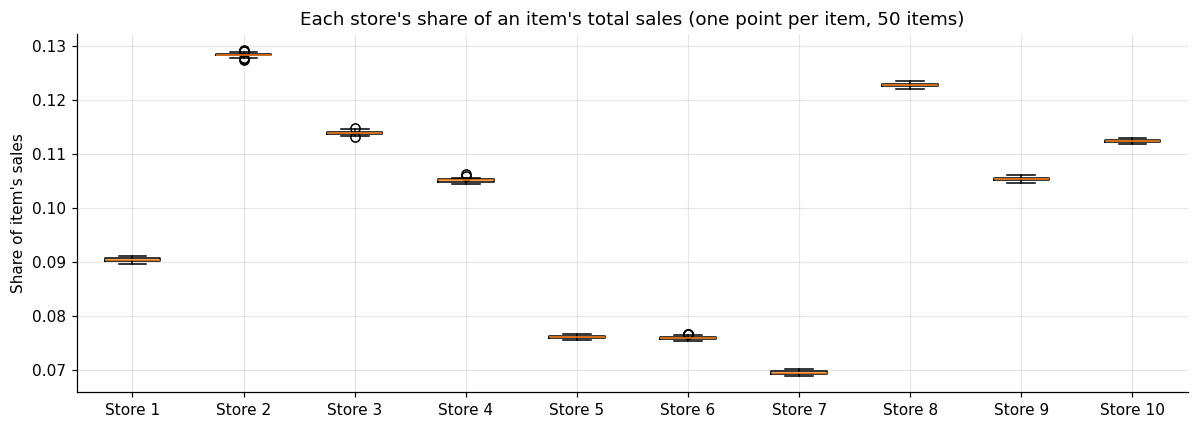

,mean,std,min,max
store,,,,
1,0.0905,0.0003,0.0897,0.0911
2,0.1283,0.0003,0.1274,0.1291
3,0.1139,0.0003,0.1130,0.1148
4,0.1051,0.0003,0.1044,0.1064
5,0.0761,0.0003,0.0756,0.0767
6,0.0760,0.0003,0.0755,0.0768
7,0.0696,0.0003,0.0690,0.0703
8,0.1228,0.0003,0.1220,0.1234
9,0.1054,0.0003,0.1045,0.1061


Largest std of a store's share across items: 0.0003


In [9]:
pivot = df.pivot_table(index="item", columns="store", values="sales", aggfunc="sum")
store_share = pivot.div(pivot.sum(axis=1), axis=0)          # each row (item) sums to 1

fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([store_share[s].values for s in store_share.columns], showfliers=True)
ax.set_xticks(range(1, len(store_share.columns) + 1))
ax.set_xticklabels([f"Store {s}" for s in store_share.columns])
ax.set(title="Each store's share of an item's total sales (one point per item, 50 items)",
       ylabel="Share of item's sales")
fig.tight_layout()
save(fig, "eda_5b_store_share")
plt.show()

display(store_share.agg(["mean", "std", "min", "max"]).T.rename_axis("store")
        .map(lambda v: f"{v:.4f}"))
print(f"Largest std of a store's share across items: {store_share.std().max():.4f}")

## 1.7 补充：从“每日销量”到“未来 7 天总需求”

我们的预测目标是 **7 天总和**，不是单日销量。这段代码用 Store 1 × Item 1 的 2017 年数据说明两者的区别：
- **上图**：每日销量，有明显的周内锯齿；
- **下图**：滚动 7 天总和，即每个日期往前连续 7 天的销量合计。任意连续 7 天都正好包含一个完整的星期，所以**星期效应被抵消**，曲线平滑得多，剩下的主要是季节、趋势和随机波动；
- 打印两条序列“相邻两天平均变化了多少百分比”，用数字说明 7 天总和更平稳。

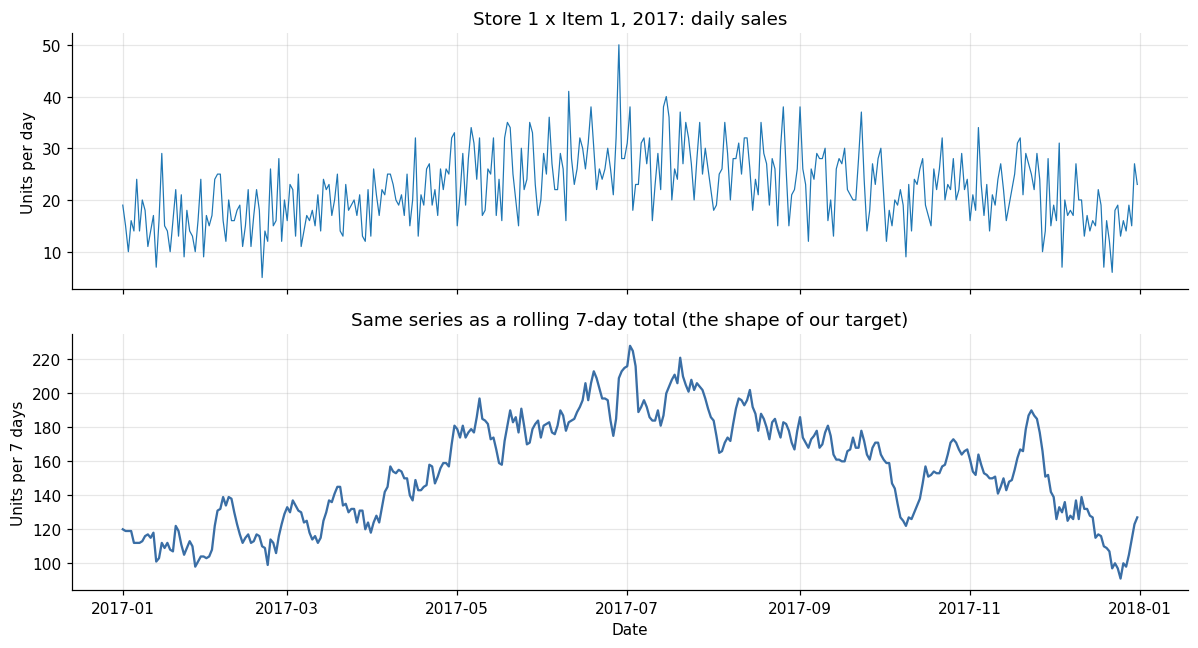

Average day-to-day change, daily sales:   32.2%
Average day-to-day change, 7-day total:   3.5%


In [10]:
ex_2017 = ex.loc["2017-01-01":"2017-12-31"]
rolling7 = ex.rolling(7).sum().loc["2017-01-01":"2017-12-31"]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(ex_2017.index, ex_2017.values, lw=0.8)
axes[0].set(title=f"Store {EXAMPLE_STORE} x Item {EXAMPLE_ITEM}, 2017: daily sales", ylabel="Units per day")
axes[1].plot(rolling7.index, rolling7.values, lw=1.5, color="#3a6ea5")
axes[1].set(title="Same series as a rolling 7-day total (the shape of our target)",
            xlabel="Date", ylabel="Units per 7 days")
fig.tight_layout()
save(fig, "eda_6_daily_vs_7day")
plt.show()

daily_change = ex_2017.pct_change().abs().mean() * 100
weekly_change = rolling7.pct_change().abs().mean() * 100
print(f"Average day-to-day change, daily sales:   {daily_change:.1f}%")
print(f"Average day-to-day change, 7-day total:   {weekly_change:.1f}%")

## 1.8 EDA 结论 → 对特征工程的启示

下表中的数字都来自上面各段代码的输出。

| 观察 | 发现 | 对特征工程的启示 |
|---|---|---|
| **Weekly pattern** | 周日最高（约为平均的 1.19 倍），周一最低（约 0.79 倍），**星期六约为星期一的 1.42 倍**；10 家店的周规律几乎完全相同。 | 我们预测的是 **7 天总和**，星期效应在 7 天内自然抵消（见 1.7 节），所以**不需要星期几特征**。如果以后改成预测单日销量，就必须加上星期几特征。 |
| **Seasonal pattern** | 7 月最高（约 1.28 倍），1 月最低（约 0.68 倍）；**夏季约为冬季的 1.66 倍**；每年形状相同，50 个商品的季节规律也几乎一样。 | 加入**月份 / 一年中的第几周**特征；加入**去年同期 7 天的销量**（往前 364 天，正好 52 周，星期也对齐）。季节转折期（如 12 月）只看最近几周的销量会明显偏差，所以这类特征很关键。 |
| **Trend** | 总销量逐年增长，2017 年约为 2013 年的 **1.35 倍**；同比增速在 4%–15% 之间波动，2017 年只有约 3.6%；10 家店增速几乎相同。 | 树模型（如 Gradient Boosting）**不能外推**到训练数据里没出现过的销量水平。所以要用**最近 7 / 14 / 28 天的销量**来反映当前水平，或者用“最近水平 ÷ 去年同期水平”这样的**比例特征**，而不是只依赖年份。 |
| **Store difference** | 同一个商品在不同门店的销量差别很大（Item 1：Store 3 约为 Store 1 的 1.26 倍；10 家店中最高的 Store 2 约为最低的 Store 7 的 1.8 倍）；Store 1 和 Store 3 的周销量高度同步（相关系数约 0.88）。每家店的份额在 50 个商品上几乎不变（标准差 ≤ 0.0003）。 | 加入**门店编号、商品编号**（或它们的历史平均销量水平）。门店之间主要是**销量高低不同**，涨跌方向基本一致。 |

### 对 ReturnRoute 方案的提醒（答辩时要能说清楚）
1. 这个数据集的规律**非常规整**：所有门店的周规律、增长速度相同，所有商品的季节规律也相同。这说明它很可能是 Kaggle 按固定规律**模拟生成**的教学数据，不是真实零售数据。PPT 里应写明“使用公开数据集验证预测方法”。
2. 因为门店之间的规律完全同步，数据里**不会出现“某家店突然缺货或需求突然变高”**这种局部变化。如果要展示 ReturnRoute 在门店之间做调拨决策的价值，需要在后续阶段加入**明确说明的情景模拟**（例如某店促销、某店断货）。
3. 数据里**没有价格、促销、库存、尺码和退货信息**，所以本阶段把“销量”当作“需求”。这一点要写进局限说明。

---
# 第二阶段：Feature Engineering（特征工程）

这是整个 Random Forest 最重要的一步之一。

Random Forest 自己并不知道“昨天”“上周”“季节性”是什么意思。原始数据只有 4 列：

```
date | store | item | sales
```

所以我们必须把这些时间信息**转换成一个个变量（特征）**交给它。转换后，每一行数据表示：

> **某家店、某个商品、站在某一天的早上：已经知道哪些历史情况？接下来 7 天会卖多少？**

例如：Store C（数据中的 Store 3）、Item 1、Date = 2017 年 10 月 1 日。模型看到的是：

```
Month = 10
Day of week = Sunday
Yesterday sales = ...
7 days ago sales = ...
Previous 7-day average = ...
Previous 28-day average = ...
```

然后学习：**在这种历史情况下，接下来 7 天通常会卖多少？**（2.8 节会用真实数据把这一行完整算出来。）

## 时间约定：最重要、也最容易出错的地方

对于日期为 **d** 的一行：

```
          ← 只能用这些历史数据（d-1 及以前）→ | ← 要预测的目标 →
 ... d-28 ... d-14 ... d-7 ... d-2   d-1    |  d   d+1 ... d+6
                                     ↑      |  ↑
                              “昨天”(lag_1)  |  “今天”早上做预测
```

- **特征**只能用 **d-1 及以前**的销量。这就像员工在 d 日早上做调拨决策时，当天还没开始卖。
- **目标 `target_7d`** = d 到 d+6 这 7 天的销量总和。
- 如果特征里混进了 d 日或以后的销量，就叫**数据泄漏（data leakage）**。模型在测试时会显得非常准，实际使用时却做不到。2.9 节会用代码自动检查有没有泄漏。

## 本阶段要生成的特征

**基础特征**（参考方案中的特征表）：

| Feature | 含义 |
|---|---|
| `store` | 哪家门店 |
| `item` | 哪个商品 |
| `year` | 年份 |
| `month` | 月份 |
| `day_of_week` | 星期几（0 = 周一 … 6 = 周日） |
| `day_of_month` | 每月第几天 |
| `week_of_year` | 一年中的第几周 |
| `is_weekend` | 是否周末 |
| `lag_1` | 前 1 天（昨天）的销量 |
| `lag_7` | 7 天前的销量 |
| `lag_14` | 14 天前的销量 |
| `lag_28` | 28 天前的销量 |
| `rolling_7` | 前 7 天的平均销量 |
| `rolling_14` | 前 14 天的平均销量 |
| `rolling_28` | 前 28 天的平均销量 |
| **Target：`target_7d`** | **未来 7 天的销量总和** |

**扩展特征**（根据 EDA 结论新增）：

| Feature | 含义 | 为什么加 |
|---|---|---|
| `last_year_7d_sum` | 去年同期 7 天的销量总和（d-364 到 d-358） | EDA 发现季节规律每年重复。364 天正好是 52 周，星期也能对齐 |
| `yoy_ratio_28` | 最近 28 天的平均销量 ÷ 去年同期 28 天的平均销量 | EDA 发现销量逐年增长，而树模型不能外推。用比例描述“今年比去年高多少”，模型就不需要外推 |

第四阶段会分别用“只有基础特征”和“基础 + 扩展特征”两种组合训练模型，用结果说明扩展特征是否真的有用。

> 特征名单（`BASE_FEATURES`、`EXTRA_FEATURES`）和窗口长度已经在 0.1 节统一定义。

## 2.1 目标变量：未来 7 天的销量总和 `target_7d`

这段代码会：
- 先建立一个“按门店 × 商品分组的销量”`g`，后面所有往前、往后移动的计算都在同一条序列内部进行；
- 在每条序列里先算“截至某一天的 7 天滚动总和”，再整体往前移 6 天，得到 **d 到 d+6 的销量总和**；
- 每条序列最后 6 天凑不满未来 7 天，所以目标值是空值（NaN），后面会删除这些行；
- 显示 Store 1 × Item 1 开头 10 天的数据，可以手动核对：第一行的 `target_7d` 应该等于前 7 天 `sales` 之和。

In [11]:
# A grouped view of sales: every shift / rolling below happens *inside* one store x item series
g = df.groupby(["store", "item"])["sales"]

# rolling(7).sum() at day x = sales of x-6 ... x ; shifting it by -6 moves it to day x-6,
# so the value stored on day d becomes the total of d ... d+6.
df[TARGET] = g.transform(lambda s: s.rolling(HORIZON).sum().shift(-(HORIZON - 1)))

display(df.loc[:9, ["date", "store", "item", "sales", TARGET]])
print("Check first row:", df.loc[0:6, "sales"].sum(), "==", df.loc[0, TARGET])

,date,store,item,sales,target_7d
0,2013-01-01,1,1,13,83.00
1,2013-01-02,1,1,11,79.00
2,2013-01-03,1,1,14,80.00
3,2013-01-04,1,1,13,75.00
4,2013-01-05,1,1,10,71.00
5,2013-01-06,1,1,12,68.00
6,2013-01-07,1,1,10,66.00
7,2013-01-08,1,1,9,68.00
8,2013-01-09,1,1,12,64.00
9,2013-01-10,1,1,9,59.00


Check first row: 83 == 83.0


## 2.2 日历特征：year、month、day_of_week、day_of_month、week_of_year、is_weekend

这段代码从日期 d 中提取日历信息。这些信息在 d 日早上就已经知道，所以**不会造成泄漏**：
- `year`、`month`、`week_of_year`：告诉模型“现在处在哪一年、哪个季节”，用来学习季节规律和趋势；
- `day_of_week`、`is_weekend`、`day_of_month`：描述预测窗口从星期几、每月第几天开始。

> 根据 EDA，7 天总和已经把星期效应抵消了，所以 `day_of_week` 和 `is_weekend` 预计作用很小。我们仍然保留它们，第八阶段用特征重要性来验证这个判断。

In [12]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek               # 0 = Monday ... 6 = Sunday
df["day_of_month"] = df["date"].dt.day
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df[["date", "year", "month", "day_of_week", "day_of_month", "week_of_year", "is_weekend"]].head(8)

,date,year,month,day_of_week,day_of_month,week_of_year,is_weekend
0,2013-01-01,2013,1,1,1,1,0
1,2013-01-02,2013,1,2,2,1,0
2,2013-01-03,2013,1,3,3,1,0
3,2013-01-04,2013,1,4,4,1,0
4,2013-01-05,2013,1,5,5,1,1
5,2013-01-06,2013,1,6,6,1,1
6,2013-01-07,2013,1,0,7,2,0
7,2013-01-08,2013,1,1,8,2,0


## 2.3 门店和商品特征：store、item

`store`（1–10）和 `item`（1–50）在原始数据里已经有了，直接作为特征使用。

**为什么用编号就可以？** Random Forest 是由很多棵决策树组成的。决策树会用“store 是否 ≤ 4”这类条件，把销量水平相近的门店分到一起。所以编号不需要有大小含义，树模型也能用好。线性回归就不行，需要先做 one-hot 编码。

这段代码只是检查这两列的取值范围，确认没有异常值。

In [13]:
print("store values:", sorted(df["store"].unique().tolist()))
print("item values :", df["item"].min(), "to", df["item"].max(), f"({df['item'].nunique()} items)")

store values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
item values : 1 to 50 (50 items)


## 2.4 滞后特征（Lag）：lag_1、lag_7、lag_14、lag_28

**lag_k = d 日往前第 k 天的销量**，在每条序列内部用 `shift(k)` 实现，把销量往后挪 k 行：
- `lag_1`：昨天卖了多少，反映最新情况；
- `lag_7`、`lag_14`、`lag_28`：1、2、4 周前**同一个星期几**卖了多少，避开了星期效应的干扰。

每条序列最前面 k 天没有更早的数据，所以这些位置会是空值。

In [14]:
for k in LAGS:
    df[f"lag_{k}"] = g.shift(k)

df.loc[25:32, ["date", "sales"] + [f"lag_{k}" for k in LAGS]]

,date,sales,lag_1,lag_7,lag_14,lag_28
25,2013-01-26,12,14.00,18.00,7.00,NaN
26,2013-01-27,12,12.00,15.00,10.00,NaN
27,2013-01-28,11,12.00,8.00,12.00,NaN
28,2013-01-29,6,11.00,7.00,5.00,13.00
29,2013-01-30,9,6.00,9.00,7.00,11.00
30,2013-01-31,13,9.00,8.00,16.00,14.00
31,2013-02-01,11,13.00,14.00,7.00,13.00
32,2013-02-02,21,11.00,12.00,18.00,10.00


## 2.5 滚动平均特征（Rolling）：rolling_7、rolling_14、rolling_28

**rolling_k = d 日之前 k 天（d-k 到 d-1）的平均销量。**

关键是**先 `shift(1)` 再 `rolling(k)`**：先把销量往后挪 1 天，保证窗口里不包含 d 日当天，再计算平均值。如果忘了 `shift(1)`，就会把“今天”的销量放进特征，造成泄漏。

- `rolling_7`：最近一周的平均销量，代表**当前销量水平**，星期效应已经抵消；
- `rolling_14`、`rolling_28`：更长的窗口，更平稳、受随机波动影响更小，但对变化反应更慢。

把三个窗口同时交给模型，它就能比较近期和稍早的水平，判断销量是在**上升还是下降**。

In [15]:
for w in WINDOWS:
    df[f"rolling_{w}"] = g.transform(lambda s, w=w: s.shift(1).rolling(w).mean())

df.loc[25:32, ["date", "sales"] + [f"rolling_{w}" for w in WINDOWS]]

,date,sales,rolling_7,rolling_14,rolling_28
25,2013-01-26,12,11.29,10.21,NaN
26,2013-01-27,12,10.43,10.57,NaN
27,2013-01-28,11,10.00,10.71,NaN
28,2013-01-29,6,10.43,10.64,10.71
29,2013-01-30,9,10.29,10.71,10.46
30,2013-01-31,13,10.29,10.86,10.39
31,2013-02-01,11,11.00,10.64,10.36
32,2013-02-02,21,10.57,10.93,10.29


## 2.6 扩展特征：last_year_7d_sum、yoy_ratio_28

这两个特征来自 EDA 的结论：

- **`last_year_7d_sum`**：去年同一个 7 天窗口（d-364 到 d-358）的销量总和。EDA 发现季节规律每年几乎一样，所以“去年这时候卖了多少”是预测季节变化最直接的线索。在 12 月这类转折期，只看最近几周的销量会明显出错，这个特征能弥补。
- **`yoy_ratio_28`**：最近 28 天的平均销量 ÷ 去年同期 28 天的平均销量，表示“今年比去年高了多少”。
  - 为什么需要它：Random Forest 的预测值不会超过训练集里见过的范围（**不能外推**）。2017 年的销量比训练期（2013–2016）都高，如果只靠 `year`，模型无法知道 2017 年该高多少。
  - 用“去年同期 × 增长比例”的思路，模型就能处理没见过的销量水平。

两个特征都需要往前看 1 年以上，所以每条序列的第一年没有值。

In [16]:
# Same 7-day window last year: rolling 7-day total ending at d-358 = sales of d-364 ... d-358
df["last_year_7d_sum"] = g.transform(
    lambda s: s.rolling(HORIZON).sum().shift(LAST_YEAR - (HORIZON - 1)))

# rolling_28 of the same date one year earlier (d-392 ... d-365)
rolling_28_last_year = df.groupby(["store", "item"])["rolling_28"].shift(LAST_YEAR)
df["yoy_ratio_28"] = df["rolling_28"] / rolling_28_last_year

df.loc[df["date"] == "2017-10-01", ["date", "store", "item", "last_year_7d_sum", "yoy_ratio_28"]].head()

,date,store,item,last_year_7d_sum,yoy_ratio_28
1734,2017-10-01,1,1,156.00,1.01
3560,2017-10-01,1,2,397.00,1.07
5386,2017-10-01,1,3,239.00,1.03
7212,2017-10-01,1,4,140.00,0.94
9038,2017-10-01,1,5,121.00,0.97


## 2.7 处理空值：删除历史不足或未来不足的行

前面的特征在每条序列的开头会产生空值，因为没有足够早的历史；目标值在结尾也会有空值，因为没有完整的未来 7 天。这段代码会：
- 统计每一列有多少空值；
- 删除**任何一个特征或目标为空**的行。

这样做的结果：
- 扩展特征需要约 1 年 + 28 天的历史，所以**可用数据从 2014 年 1 月底开始**；
- 每条序列的最后 6 天也会被删除。

为了公平比较，基础特征组和扩展特征组都使用**同一批行**。

In [17]:
ALL_FEATURES = BASE_FEATURES + EXTRA_FEATURES
display(df[ALL_FEATURES + [TARGET]].isna().sum().to_frame("missing values").T)

before = len(df)
feat = df.dropna(subset=ALL_FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows before: {before:,} | after: {len(feat):,} | dropped: {before - len(feat):,}")
print("Usable dates:", feat["date"].min().date(), "to", feat["date"].max().date())

,store,item,year,month,day_of_week,day_of_month,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_7,rolling_14,rolling_28,last_year_7d_sum,yoy_ratio_28,target_7d
missing values,0,0,0,0,0,0,0,0,500,3500,7000,14000,3500,7000,14000,182000,196000,3000


Rows before: 913,000 | after: 714,000 | dropped: 199,000
Usable dates: 2014-01-28 to 2017-12-25


## 2.8 看一个完整的例子：Store C（Store 3）× Item 1，2017 年 10 月 1 日

这段代码把这一行的特征，用“模型看到了什么”的方式打印出来，并显示它要预测的目标，也就是 10 月 1 日到 7 日的实际销量总和。

同时，它会**直接从原始销量里手动重算**几个关键数字（昨天的销量、前 7 天平均、未来 7 天总和），和特征表里的值对比。两边一致，说明特征计算正确。

> PPT 里的 Store A / B / C 对应数据集里的 Store 1 / 2 / 3。

In [18]:
ex_store, ex_item, ex_date = 3, 1, pd.Timestamp("2017-10-01")

row = feat[(feat["store"] == ex_store) & (feat["item"] == ex_item) & (feat["date"] == ex_date)].iloc[0]
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print(f"Store {STORE_NAME[ex_store]} (dataset store {ex_store}), Item {ex_item}, Date = {ex_date.date()}")
print("-" * 52)
print("What the model sees:")
print(f"  Month                    = {row.month}")
print(f"  Day of week              = {DOW[row.day_of_week]}")
print(f"  Yesterday sales (lag_1)  = {row.lag_1:.0f}")
print(f"  7 days ago sales         = {row.lag_7:.0f}")
print(f"  14 days ago sales        = {row.lag_14:.0f}")
print(f"  28 days ago sales        = {row.lag_28:.0f}")
print(f"  Previous 7-day average   = {row.rolling_7:.1f}")
print(f"  Previous 14-day average  = {row.rolling_14:.1f}")
print(f"  Previous 28-day average  = {row.rolling_28:.1f}")
print(f"  Same 7 days last year    = {row.last_year_7d_sum:.0f}")
print(f"  This year / last year    = {row.yoy_ratio_28:.2f}")
print("-" * 52)
print(f"What it must learn to predict: sales of Oct 1-7 = {row[TARGET]:.0f}")

# ---- Recompute from the raw sales to prove the features are right ----
raw_series = df[(df["store"] == ex_store) & (df["item"] == ex_item)].set_index("date")["sales"]
day = pd.Timedelta(days=1)
checks = {
    "lag_1":     (raw_series[ex_date - day], row.lag_1),
    "rolling_7": (raw_series[ex_date - 7 * day: ex_date - day].mean(), row.rolling_7),
    TARGET:      (raw_series[ex_date: ex_date + 6 * day].sum(), row[TARGET]),
}
for name, (manual, table) in checks.items():
    print(f"check {name:10s}: manual = {manual:8.2f} | feature table = {table:8.2f} | "
          f"{'OK' if np.isclose(manual, table) else 'MISMATCH'}")

Store C (dataset store 3), Item 1, Date = 2017-10-01
----------------------------------------------------
What the model sees:
  Month                    = 10
  Day of week              = Sunday
  Yesterday sales (lag_1)  = 28
  7 days ago sales         = 36
  14 days ago sales        = 37
  28 days ago sales        = 30
  Previous 7-day average   = 26.4
  Previous 14-day average  = 27.4
  Previous 28-day average  = 28.9
  Same 7 days last year    = 190
  This year / last year    = 1.04
----------------------------------------------------
What it must learn to predict: sales of Oct 1-7 = 199
check lag_1     : manual =    28.00 | feature table =    28.00 | OK
check rolling_7 : manual =    26.43 | feature table =    26.43 | OK
check target_7d : manual =   199.00 | feature table =   199.00 | OK


## 2.9 自动检查数据泄漏

2.8 节只核对了一行。这段代码会**随机抽取 300 行**，对每一行都直接从原始销量里，按照定义重新计算所有时间相关的特征和目标：
- 特征只能用 d-1 及以前的数据；
- 目标只能用 d 到 d+6 的数据。

如果任何一个值和特征表里的不一致，代码会报错并停止运行。只有全部一致，才会打印“通过”。

In [19]:
rng = np.random.default_rng(42)
sample = feat.iloc[rng.choice(len(feat), size=300, replace=False)]
series = {key: s.set_index("date")["sales"] for key, s in df.groupby(["store", "item"])}
D = pd.Timedelta(days=1)

def expected(r):
    s, d = series[(r.store, r.item)], r.date
    out = {f"lag_{k}": s[d - k * D] for k in LAGS}
    out.update({f"rolling_{w}": s[d - w * D: d - D].mean() for w in WINDOWS})
    out["last_year_7d_sum"] = s[d - 364 * D: d - 358 * D].sum()
    out["yoy_ratio_28"] = s[d - 28 * D: d - D].mean() / s[d - 392 * D: d - 365 * D].mean()
    out[TARGET] = s[d: d + 6 * D].sum()
    return out

for r in sample.itertuples():
    for name, value in expected(r).items():
        assert np.isclose(getattr(r, name), value), f"Mismatch in {name} at {r.date.date()}"

print("PASSED: all lag / rolling / last-year features use only data before date d,")
print("        and target_7d equals the sales of d ... d+6, for 300 random rows.")

PASSED: all lag / rolling / last-year features use only data before date d,
        and target_7d equals the sales of d ... d+6, for 300 random rows.


## 2.10 划分训练集和测试集（按时间）

时间序列**不能随机打乱**来划分数据。随机划分会让模型在训练时“看到”测试期前后的日子，相当于偷看了未来。这段代码按时间切分：

| 集合 | 日期 d 的范围 | 说明 |
|---|---|---|
| **train** | 2014-01-28 到 2016-12-25 | 目标窗口 d…d+6 最晚到 2016-12-31，**完全不碰 2017 年** |
| （丢弃） | 2016-12-26 到 2016-12-31 | 这些行的目标窗口会跨进 2017 年，为了干净地隔开训练集和测试集，不使用它们 |
| **test** | 2017-01-01 到 2017-12-25 | 模拟“2017 年每天早上做一次预测”，用来评估模型 |

> 测试集的特征会用到 2016 年底和 2017 年当年已经发生的销量，这是允许的。真实使用时，系统每天早上也能看到截至昨天的所有历史数据。

In [20]:
TRAIN_END = pd.Timestamp("2016-12-31") - pd.Timedelta(days=HORIZON - 1)   # 2016-12-25
TEST_START = pd.Timestamp("2017-01-01")

feat["split"] = np.select(
    [feat["date"] <= TRAIN_END, feat["date"] >= TEST_START],
    ["train", "test"], default="gap")

summary = (feat.groupby("split")
           .agg(rows=("date", "size"), first_date=("date", "min"), last_date=("date", "max"),
                avg_target=(TARGET, "mean"))
           .loc[["train", "gap", "test"]])
display(summary)
feat = feat[feat["split"] != "gap"].reset_index(drop=True)

,rows,first_date,last_date,avg_target
split,,,,
train,531500,2014-01-28,2016-12-25,374.75
gap,3000,2016-12-26,2016-12-31,288.30
test,179500,2017-01-01,2017-12-25,413.48


## 2.11 初步检查：哪些特征和目标最相关？

这段代码在**训练集**上计算每个特征与 `target_7d` 的相关系数，并画成横向柱状图：
- 越接近 1，说明这个特征越大，未来 7 天的需求也越大；
- 这只是一个初步检查，只能反映“直线关系”。决策树还能利用非线性关系，比如 `month` 和需求不是直线关系，但对模型仍然有用。真正的重要性要到第八阶段看模型的特征重要性。
- `store`、`item` 只是编号，它们的相关系数没有实际意义，所以不画进图里。

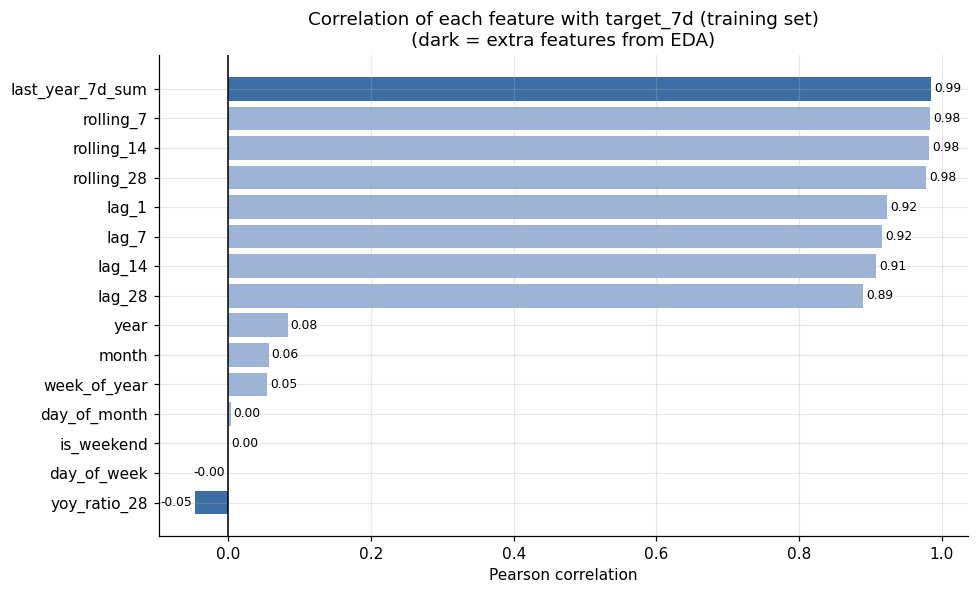

In [21]:
train = feat[feat["split"] == "train"]
corr_cols = [c for c in ALL_FEATURES if c not in ("store", "item")]
corr = train[corr_cols].corrwith(train[TARGET]).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#3a6ea5" if c in EXTRA_FEATURES else "#9db4d6" for c in corr.index]
bars = ax.barh(corr.index, corr.values, color=colors)
ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.axvline(0, color="black", lw=1)
ax.set(title="Correlation of each feature with target_7d (training set)\n(dark = extra features from EDA)",
       xlabel="Pearson correlation")
fig.tight_layout()
fig.savefig(FIG_DIR / "fe_1_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**怎么读这张图：**
- `last_year_7d_sum` 和三个滚动平均与目标的相关系数都达到 0.98–0.99，`lag_k` 约为 0.9。这些数字这么高，有一部分只是因为不同门店、不同商品的销量规模差别很大（大商品的历史销量和未来销量都大），并不代表模型已经能把误差压得很低。
- 单日的 `lag_k` 比 7 天平均的 `rolling_k` 低，原因是单日销量的随机波动更大。
- `day_of_week`、`is_weekend`、`day_of_month` 的相关系数几乎为 0，和 EDA 的判断一致：7 天总和已经抵消了星期效应。
- `yoy_ratio_28` 的相关系数接近 0，**但这不代表它没用**。它是一个比例，本身不带销量规模，需要和 `last_year_7d_sum` 组合起来用（去年同期 × 增长比例）。这种组合关系，单个特征的相关系数看不出来，要到第四阶段用模型结果来判断。

## 2.12 小结

| 步骤 | 结果 |
|---|---|
| 目标 | `target_7d` = d 到 d+6 的销量总和 |
| 基础特征（15 个） | `store`、`item`，6 个日历特征，4 个滞后特征，3 个滚动平均特征 |
| 扩展特征（2 个） | `last_year_7d_sum`（去年同期），`yoy_ratio_28`（同比增长比例） |
| 防泄漏 | 特征只用 d-1 及以前的数据；300 行随机抽查全部通过 |
| 数据划分 | 按时间切分：train = 2014-01-28 到 2016-12-25（531,500 行），test = 2017-01-01 到 2017-12-25（179,500 行）；中间丢弃 6 天，彻底隔开 |
| 输出 | 内存中的特征表 `feat`，后面各阶段直接使用 |

---
# 第三阶段：Baseline（基准模型）

在标准的机器学习流程里，不应该一上来就用 Random Forest，而是**先有一个非常简单的 benchmark（基准）**。

## Last Week Baseline（上周基准）

$$\text{Future Demand}_{\,d \dots d+6} = \text{Last Week Demand}_{\,d-7 \dots d-1}$$

简单理解就是：**“我假设下周卖得跟上周差不多。”** 比如过去 7 天卖了 64 件，baseline 就预测未来 7 天也卖 64 件。

## 为什么一定要先做这个？

| 情况 | Baseline MAE | Random Forest MAE | 结论 |
|---|---|---|---|
| ❌ | 10 | 15 | Random Forest 比简单规则还差，**白做了** |
| ✅ | 15 | 9 | 才能说：**AI model improves demand forecasting compared with a simple historical rule.** |

这句话正是 Presentation 里回答“为什么需要 AI”的核心证据。

## 本阶段会做什么
1. 计算 **Last Week Baseline**（主要基准，和上面的公式完全一致）；
2. 另外计算两个“更聪明”的简单规则作为对照：**4 周平均**，以及**去年同期 × 同比增长**。原因是：如果 Random Forest 只赢了最弱的规则，答辩时容易被追问“那跟稍微聪明一点的规则比呢？”；
3. 在 **2017 年测试集**上统一计算误差（MAE、RMSE、WAPE、Bias），并按月份、按门店拆开来看；
4. 第五阶段会直接和 Random Forest 对比。

> 所有 baseline 都**不需要训练**，只用 d-1 及以前的数据，所以和 Random Forest 用的信息完全一样，比较是公平的。

## 3.1 计算三个 baseline 的预测值

这段代码先从特征表里取出 **2017 年测试集**（baseline 不需要训练，所以用不到训练集），再直接用已有的特征算出预测值，不需要训练任何模型：

| Baseline | 公式 | 含义 |
|---|---|---|
| **Last Week**（主要基准） | `rolling_7 × 7` | 过去 7 天（d-7 到 d-1）的销量总和。“下周 = 上周” |
| 4-Week Average | `rolling_28 × 7` | 过去 28 天的平均每周销量，更平稳，但对变化反应更慢 |
| Last Year × Growth | `last_year_7d_sum × yoy_ratio_28` | 去年同期 7 天的销量 × 今年比去年的增长比例。同时考虑了季节和趋势 |

`rolling_7` 是平均每天的销量，所以乘以 7 就是过去 7 天的总和。

In [22]:
test = feat[feat["split"] == "test"].copy()
print(f"Test set: {len(test):,} rows | {test['date'].min().date()} to {test['date'].max().date()}")
print(f"Average actual 7-day demand in test set: {test[TARGET].mean():.1f} units")

BASELINES = {
    "Last Week":          test["rolling_7"] * 7,
    "4-Week Average":     test["rolling_28"] * 7,
    "Last Year x Growth": test["last_year_7d_sum"] * test["yoy_ratio_28"],
}
for name, pred in BASELINES.items():
    test[f"pred_{name}"] = pred

cols = ["date", "store", "item", "rolling_7", "rolling_28", "last_year_7d_sum", "yoy_ratio_28",
        TARGET] + [f"pred_{n}" for n in BASELINES]
test.loc[(test["store"] == 3) & (test["item"] == 1), cols].head(5)

Test set: 179,500 rows | 2017-01-01 to 2017-12-25
Average actual 7-day demand in test set: 413.5 units


,date,store,item,rolling_7,rolling_28,last_year_7d_sum,yoy_ratio_28,target_7d,pred_Last Week,pred_4-Week Average,pred_Last Year x Growth
143263,2017-01-01,3,1,19.71,21.93,117.00,1.17,138.00,138.00,153.50,136.31
143264,2017-01-02,3,1,19.14,21.57,118.00,1.15,136.00,134.00,151.00,136.28
143265,2017-01-03,3,1,19.86,21.25,118.00,1.14,137.00,139.00,148.75,135.02
143266,2017-01-04,3,1,19.14,21.36,123.00,1.16,131.00,134.00,149.50,142.82
143267,2017-01-05,3,1,19.86,21.50,126.00,1.16,131.00,139.00,150.50,145.59


## 3.2 评价指标

所有模型都用 0.1 节定义的 `evaluate()` 函数计算 4 个误差指标，保证比较口径一致。这段代码用一个小例子检查它的计算：

| 指标 | 计算方式 | 怎么理解 |
|---|---|---|
| **MAE**（平均绝对误差） | 平均每次预测差了多少件 | **主要指标**。最直观：“平均每次预测偏差 X 件” |
| **RMSE**（均方根误差） | 误差平方的平均值再开根号 | 对**大错误**惩罚更重。偶尔严重预测错，RMSE 会明显变大 |
| **WAPE**（加权绝对百分比误差） | 总绝对误差 ÷ 总实际销量 | 用百分比表示，不受销量规模影响，方便和别的数据比较 |
| **Bias**（偏差） | 平均（预测 − 实际） | 正数 = 系统性**高估**，负数 = 系统性**低估** |

对 ReturnRoute 来说，Bias 很重要：长期低估需求，会让系统少把退货送到真正缺货的门店；长期高估，又会造成不必要的调拨。

In [23]:
# actual = [10, 20], predicted = [12, 17]
print(evaluate(np.array([10, 20]), np.array([12, 17])))

MAE       2.50
RMSE      2.55
WAPE %   16.67
Bias     -0.50
dtype: float64


## 3.3 整体结果：三个 baseline 在 2017 年测试集上的表现

这段代码会：
- 对每个 baseline 计算 4 个指标，汇总成一张表；
- 再加一行**“理论最佳（随机波动下限）”**作为参考。EDA 发现这份数据的随机波动接近泊松分布：即使知道真实的平均需求，7 天销量本身也会随机上下波动。按泊松分布估算，任何模型的 MAE 大约都不可能低于这个值。如果 Random Forest 的结果**低于**它，大概率是出现了数据泄漏。

In [24]:
baseline_results = pd.DataFrame({name: evaluate(test[TARGET], test[f"pred_{name}"]) for name in BASELINES}).T

# Approximate floor: for Poisson noise with mean y, E|Y - mean| ≈ sqrt(2 * mean / pi)
noise_floor_mae = np.mean(np.sqrt(2 * test[TARGET] / np.pi))
baseline_results.loc["Noise floor (approx.)"] = [noise_floor_mae, np.nan,
                                        noise_floor_mae * len(test) / test[TARGET].sum() * 100, np.nan]
display(baseline_results)

best = baseline_results.drop("Noise floor (approx.)")["MAE"].idxmin()
print(f"Main benchmark  : Last Week  -> MAE = {baseline_results.loc['Last Week', 'MAE']:.1f} units")
print(f"Best simple rule: {best} -> MAE = {baseline_results.loc[best, 'MAE']:.1f} units")

,MAE,RMSE,WAPE %,Bias
Last Week,26.91,36.87,6.51,-0.41
4-Week Average,31.13,42.98,7.53,-0.84
Last Year x Growth,25.39,32.81,6.14,0.56
Noise floor (approx.),15.70,NaN,3.80,NaN


Main benchmark  : Last Week  -> MAE = 26.9 units
Best simple rule: Last Year x Growth -> MAE = 25.4 units


## 3.4 把结果画成柱状图（可直接放进 PPT）

这段代码把三个 baseline 的 MAE 画成柱状图，并用虚线标出“随机波动下限”。

图的含义：柱子和虚线之间的距离，就是**任何模型最多还能改进的空间**。第五阶段会把 Random Forest 的柱子加进来比较。

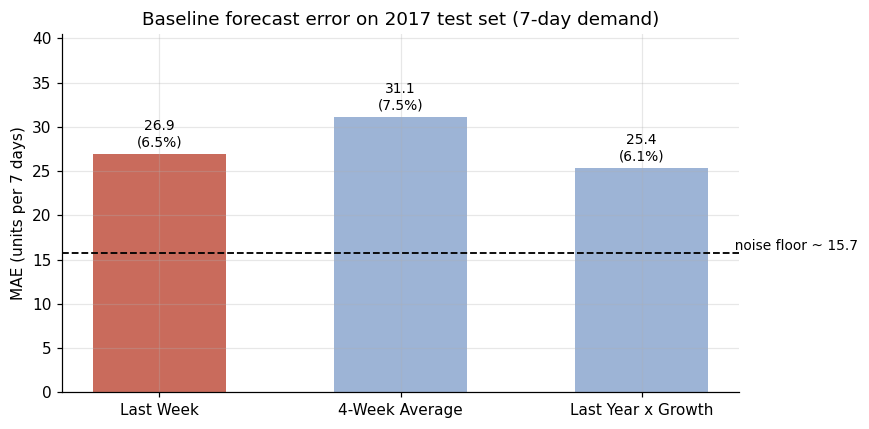

In [25]:
plot_res = baseline_results.drop("Noise floor (approx.)")
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#c96b5c", "#9db4d6", "#9db4d6"]
bars = ax.bar(plot_res.index, plot_res["MAE"], color=colors, width=0.55)
ax.bar_label(bars, labels=[f"{m:.1f}\n({w:.1f}%)" for m, w in zip(plot_res["MAE"], plot_res["WAPE %"])],
             fontsize=9, padding=3)
ax.axhline(noise_floor_mae, color="black", ls="--", lw=1.2)
ax.text(2.35, noise_floor_mae, f"  noise floor ~ {noise_floor_mae:.1f}", va="bottom", fontsize=9)
ax.set(title="Baseline forecast error on 2017 test set (7-day demand)",
       ylabel="MAE (units per 7 days)", ylim=(0, plot_res["MAE"].max() * 1.3))
fig.tight_layout()
fig.savefig(FIG_DIR / "bl_1_baseline_mae.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.5 按月份拆开看：简单规则在什么时候最容易出错？

整体平均误差可能掩盖问题。这段代码按**预测日期所在的月份**分别计算每个 baseline 的 WAPE，并画成折线图。

重点看**季节转折期**：
- 比如 12 月需求从 11 月的高位快速下降，“下周 = 上周”会严重**高估**；
- 3 到 4 月需求快速上升，它又会**低估**。

这正是 AI 模型可以利用季节特征改进的地方，也是 ReturnRoute 的业务风险所在：在需求下滑的时候，按“上周销量”调拨，会把退货送进马上要变冷的门店。

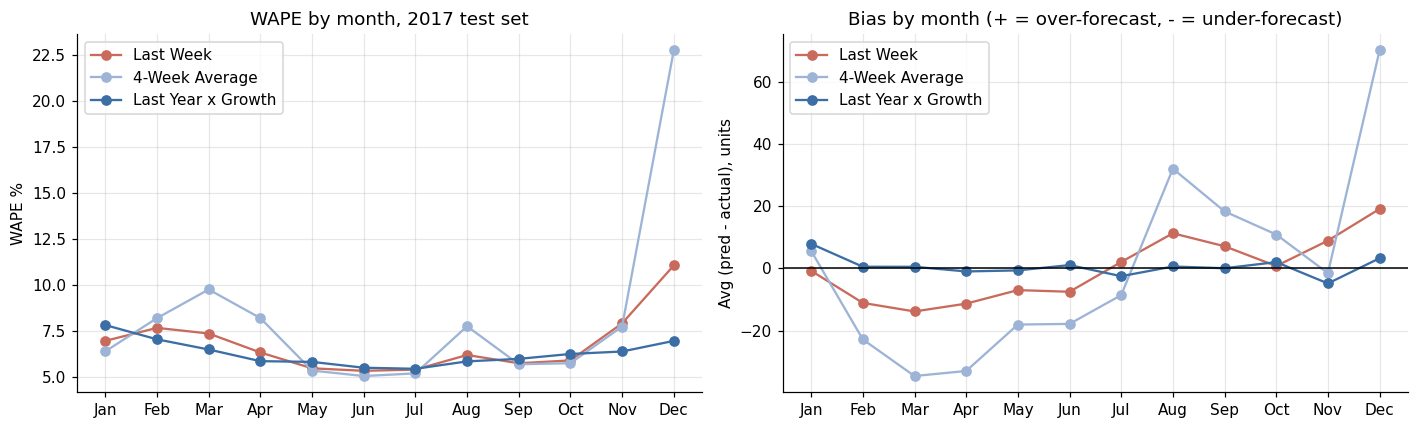

month,1,2,3,4,5,6,7,8,9,10,11,12
Last Week,6.90,7.70,7.30,6.30,5.50,5.30,5.40,6.20,5.70,5.90,7.90,11.00
4-Week Average,6.40,8.20,9.70,8.20,5.30,5.00,5.20,7.70,5.70,5.70,7.70,22.80
Last Year x Growth,7.80,7.00,6.50,5.80,5.80,5.50,5.40,5.80,6.00,6.20,6.40,6.90


In [26]:
test["month"] = test["date"].dt.month
monthly = pd.DataFrame({
    name: test.groupby("month").apply(
        lambda d, n=name: np.sum(np.abs(d[f"pred_{n}"] - d[TARGET])) / d[TARGET].sum() * 100,
        include_groups=False)
    for name in BASELINES})
monthly_bias = pd.DataFrame({
    name: test.groupby("month").apply(
        lambda d, n=name: np.mean(d[f"pred_{n}"] - d[TARGET]), include_groups=False)
    for name in BASELINES})

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(BASELINES, ["#c96b5c", "#9db4d6", "#3a6ea5"]):
    axes[0].plot(MONTHS, monthly[name].values, marker="o", label=name, color=color)
    axes[1].plot(MONTHS, monthly_bias[name].values, marker="o", label=name, color=color)
axes[0].set(title="WAPE by month, 2017 test set", ylabel="WAPE %")
axes[1].axhline(0, color="black", lw=1)
axes[1].set(title="Bias by month (+ = over-forecast, - = under-forecast)", ylabel="Avg (pred - actual), units")
axes[0].legend(); axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "bl_2_error_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

display(monthly.T.round(1))

## 3.6 看一条具体序列：Store C × Item 1 在 2017 年

数字表格比较抽象。这段代码把 Store C（数据中的 Store 3）× Item 1 在 2017 年的**真实 7 天需求**，和 Last Week、Last Year × Growth 两个 baseline 的预测画在一起。

可以直接看到：Last Week 的曲线总是比真实值**慢一拍**，它只是把上周的数字搬过来。在需求转折的地方，这种滞后最明显。

> 注意：这条序列的销量规模较小（每周约 100 到 200 件），随机波动占误差的大部分，所以三个 baseline 的 MAE 很接近（都在 16 件左右）。baseline 之间的差距要看 3.3 节的整体结果和 3.5 节的月度结果。

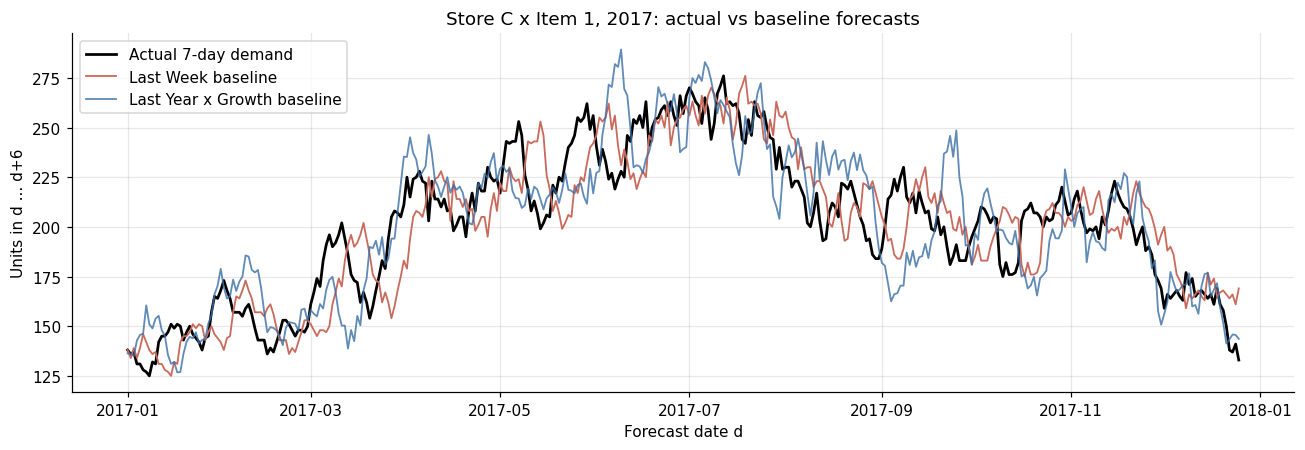

Store C x Item 1, MAE in 2017:
  Last Week              16.6
  4-Week Average         16.3
  Last Year x Growth     16.2


In [27]:
one = test[(test["store"] == 3) & (test["item"] == 1)].set_index("date")

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(one.index, one[TARGET], color="black", lw=1.8, label="Actual 7-day demand")
ax.plot(one.index, one["pred_Last Week"], color="#c96b5c", lw=1.2, label="Last Week baseline")
ax.plot(one.index, one["pred_Last Year x Growth"], color="#3a6ea5", lw=1.2, alpha=0.8,
        label="Last Year x Growth baseline")
ax.set(title="Store C x Item 1, 2017: actual vs baseline forecasts", xlabel="Forecast date d",
       ylabel="Units in d ... d+6")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "bl_3_example_series.png", dpi=150, bbox_inches="tight")
plt.show()

print("Store C x Item 1, MAE in 2017:")
for name in BASELINES:
    print(f"  {name:20s} {np.mean(np.abs(one[f'pred_{name}'] - one[TARGET])):6.1f}")

## 3.7 只看 ReturnRoute 演示用的三家店（Store A / B / C）

Presentation 里的场景只有 A、B、C 三家门店，对应数据中的 Store 1、2、3。这段代码只看这三家店，检查 baseline 在不同门店的表现是否一致：
- 门店销量规模不同，所以 **MAE**（件数）会不同；
- **WAPE**（百分比）可以直接横向比较。

In [28]:
abc = test[test["store"].isin([1, 2, 3])]
by_store = pd.concat({
    f"Store {'ABC'[s - 1]}": pd.DataFrame({n: evaluate(d[TARGET], d[f"pred_{n}"]) for n in BASELINES}).T
    for s, d in abc.groupby("store")})
display(by_store[["MAE", "WAPE %", "Bias"]])

MAE  WAPE %  Bias
Store A Last Week          25.28    6.75 -0.36
        4-Week Average     29.09    7.77 -0.71
        Last Year x Growth 24.39    6.52  0.70
Store B Last Week          31.89    6.01 -0.54
        4-Week Average     38.68    7.29 -1.14
        Last Year x Growth 28.91    5.45  0.56
Store C Last Week          29.15    6.18 -0.46
        4-Week Average     34.60    7.34 -0.97
        Last Year x Growth 27.41    5.82  0.57

## 3.8 小结：Random Forest 要达到什么才算“有用”？

（数字来自上面各段代码的输出。）

| | MAE（件 / 7 天） | WAPE |
|---|---:|---:|
| **Last Week**（主要基准） | **26.9** | 6.5% |
| 4-Week Average | 31.1 | 7.5% |
| Last Year × Growth（最强的简单规则） | 25.4 | 6.1% |
| 随机波动下限（约） | 15.7 | 3.8% |

**几个关键发现：**
- “下周 = 上周”平均每次差约 27 件，误差约为实际需求的 6.5%；
- 它在**季节转折期**错得最多：2 到 4 月需求上升时平均**低估** 11 到 14 件，12 月需求下降时平均**高估**约 19 件，WAPE 升到 11%；
- “去年同期 × 增长”全年都比较稳定，偏差接近 0，是最强的简单规则；
- 离随机波动下限（约 15.7）还有约 10 件的差距，这是模型最多能改进的空间。

**第五阶段的判断标准：**
1. **最低要求**：Random Forest 的 MAE 要**低于 Last Week**，才能说 *“AI model improves demand forecasting compared with a simple historical rule.”*
2. **更有说服力**：MAE 也要**低于 Last Year × Growth**，说明模型赢的不只是最简单的规则；
3. **合理性检查**：MAE **不应低于随机波动下限**，否则要回头检查是否有数据泄漏。

**Presentation 里可以用的一句话：**
> “A naive ‘next week = last week’ rule is wrong by about 26.9 units per item-store-week, and it is worst at seasonal turning points such as December, when it over-forecasts by about 19 units. This is exactly when a wrong transfer decision is most costly.”

---
# 第四阶段：训练 Random Forest

现在才正式进入 AI。

**输入与目标：**

$$X = [\,store,\ item,\ month,\ day\_of\_week,\ lag_1,\ lag_7,\ lag_{14},\ rolling_7,\ rolling_{28}\,] \qquad y = Next\ 7\ Day\ Demand$$

**Random Forest 的工作方式：**

```
Historical Data → Feature Engineering → Random Forest
                                          ├ Tree 1  → 67
                                          ├ Tree 2  → 72
                                          ├ Tree 3  → 69
                                          ├ ...
                                          └ Tree 100 → 71
                                                ↓
                                   Average → Predicted 7-day demand ≈ 70
```

每棵树都在随机抽取的一部分数据和特征上训练，所以每棵树的判断都略有不同。把 100 棵树的预测取平均，可以抵消单棵树的偶然错误，结果比任何一棵树都更稳定。

## 4.1 定义三组候选特征

我们准备了三组特征，看看“给模型更多信息”是否真的能提高准确度：

| 方案 | 特征 | 来源 |
|---|---|---|
| **RF-1 Core** | `store`、`item`、`month`、`day_of_week`、`lag_1`、`lag_7`、`lag_14`、`rolling_7`、`rolling_28`（9 个） | 方案中的输入 X |
| **RF-2 Full base** | 第四阶段的全部 15 个基础特征（在 RF-1 上加了 `year`、`day_of_month`、`week_of_year`、`is_weekend`、`lag_28`、`rolling_14`） | 特征工程表 |
| **RF-3 Base + EDA** | 15 个基础特征 + `last_year_7d_sum`、`yoy_ratio_28`（17 个） | 根据 EDA 新增 |

In [29]:
FEATURE_SETS = {
    "RF-1 Core":       ["store", "item", "month", "day_of_week",
                        "lag_1", "lag_7", "lag_14", "rolling_7", "rolling_28"],
    "RF-2 Full base":  BASE_FEATURES,
    "RF-3 Base + EDA": BASE_FEATURES + EXTRA_FEATURES,
}
for name, cols in FEATURE_SETS.items():
    print(f"{name:16s} ({len(cols):2d}): {cols}")

RF-1 Core        ( 9): ['store', 'item', 'month', 'day_of_week', 'lag_1', 'lag_7', 'lag_14', 'rolling_7', 'rolling_28']
RF-2 Full base   (15): ['store', 'item', 'year', 'month', 'day_of_week', 'day_of_month', 'week_of_year', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_7', 'rolling_14', 'rolling_28']
RF-3 Base + EDA  (17): ['store', 'item', 'year', 'month', 'day_of_week', 'day_of_month', 'week_of_year', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_7', 'rolling_14', 'rolling_28', 'last_year_7d_sum', 'yoy_ratio_28']


## 4.2 设置 Random Forest 的参数

这段代码定义一个函数，用固定参数创建 Random Forest（第七阶段会再比较其他参数）。每个参数的含义：

| 参数 | 取值 | 含义 |
|---|---|---|
| `n_estimators` | 100 | 森林里有 **100 棵树**，最后取它们预测值的平均 |
| `min_samples_leaf` | 5 | 每个叶子节点（树的最末端）至少包含 5 个训练样本。这样树不会为了个别样本过度细分，减少**过拟合**（死记训练数据） |
| `max_features` | 0.5 | 每次分裂节点时，只从**随机挑选的一半特征**里选最好的。这让各棵树之间更不一样，取平均的效果更好 |
| `n_jobs` | -1 | 使用电脑的全部 CPU 核心并行训练，速度更快 |
| `random_state` | 42 | 固定随机种子，保证结果可以复现 |

这些是 Random Forest 的常用设置。本项目的重点是对比“有没有 AI”，所以没有做大规模调参。

In [30]:
def make_rf():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                 n_jobs=-1, random_state=SEED)

print(make_rf())

RandomForestRegressor(max_features=0.5, min_samples_leaf=5, n_jobs=-1,
                      random_state=42)


## 4.3 用验证集选择特征方案（不能用测试集来选！）

**为什么不直接在 2017 年测试集上比较三个方案，然后挑最好的？**
因为那样就是**用测试集做了选择**，测试结果会显得过于乐观，就像先看了考试答案再选做题方法。正确的做法是在训练期内部再切出一段**验证集**：

| 用途 | 日期范围 |
|---|---|
| 训练（fit） | 2014-01-28 到 2015-12-25 |
| 验证（选方案） | 2016-01-01 到 2016-12-25 |
| 测试（最后只用一次） | 2017 年，到第五阶段才使用 |

**选择规则（训练之前就定好）：**
1. 先比较验证集上的 **MAE**，越低越好；
2. 如果几个方案的 MAE 相差在 **2% 以内**，就选 **|Bias| 更小**的方案。原因是 ReturnRoute 会根据预测做调拨，系统性高估或低估都会让调拨决策出现偏差（见 3.5 节）。

这段代码会分别训练三个方案，在 2016 年验证集上评估，并按上面的规则自动选出最终方案。

In [31]:
train_all = feat[feat["split"] == "train"]
fit_part = train_all[train_all["date"] <= "2015-12-25"]
val_part = train_all[train_all["date"] >= "2016-01-01"]
print(f"Fit: {len(fit_part):,} rows | Validation: {len(val_part):,} rows")

val_rows = {}
for name, cols in FEATURE_SETS.items():
    t0 = time.time()
    model = make_rf().fit(fit_part[cols], fit_part[TARGET])
    val_rows[name] = evaluate(val_part[TARGET], model.predict(val_part[cols]))
    print(f"  trained {name:16s} in {time.time() - t0:4.0f}s")

val_rows["Last Week (baseline)"] = evaluate(val_part[TARGET], val_part["rolling_7"] * 7)
val_table = pd.DataFrame(val_rows).T
display(val_table)

# ---- selection rule: lowest MAE; among models within 2% of it, the smallest |Bias| ----
cand = val_table.loc[list(FEATURE_SETS)]
close = cand[cand["MAE"] <= cand["MAE"].min() * 1.02]
FINAL = close["Bias"].abs().idxmin()
print(f"Models within 2% of the best validation MAE: {list(close.index)}")
print(f"==> Selected feature set: {FINAL}")

Fit: 348,500 rows | Validation: 180,000 rows


  trained RF-1 Core        in    5s


  trained RF-2 Full base   in    8s


  trained RF-3 Base + EDA  in   11s


,MAE,RMSE,WAPE %,Bias
RF-1 Core,22.02,29.76,5.53,-1.67
RF-2 Full base,19.19,25.31,4.82,-0.64
RF-3 Base + EDA,18.86,24.78,4.74,-6.57
Last Week (baseline),26.29,35.94,6.61,-0.50


Models within 2% of the best validation MAE: ['RF-2 Full base', 'RF-3 Base + EDA']
==> Selected feature set: RF-2 Full base


## 4.4 用全部训练数据重新训练最终模型

选好方案后，用**全部训练数据**（2014-01-28 到 2016-12-25，包括刚才的验证期）重新训练一次。训练数据越多，模型学到的规律越完整。

为了在第五阶段做透明的对比，这段代码也会用全部训练数据重新训练另外两个方案。但**最终结论只看 4.3 节选出的方案**。

In [32]:
models, test_pred = {}, {}
for name, cols in FEATURE_SETS.items():
    t0 = time.time()
    models[name] = make_rf().fit(train_all[cols], train_all[TARGET])
    test_pred[name] = models[name].predict(test[cols])
    print(f"  {name:16s} trained on {len(train_all):,} rows in {time.time() - t0:4.0f}s"
          + ("   <-- FINAL MODEL" if name == FINAL else ""))

final_model, final_cols = models[FINAL], FEATURE_SETS[FINAL]
test["pred_RF"] = test_pred[FINAL]

  RF-1 Core        trained on 531,500 rows in    9s


  RF-2 Full base   trained on 531,500 rows in   14s   <-- FINAL MODEL


  RF-3 Base + EDA  trained on 531,500 rows in   19s


## 4.5 打开“森林”看一看：每棵树各预测了多少？

这段代码用 Store C（数据中的 Store 3）× Item 1、2017-10-01 这一行做例子（和 2.8 节是同一行）：
- 分别取出 100 棵树各自的预测值，显示前 3 棵和最后 1 棵；
- 计算 100 个预测值的平均，验证它**正好等于**整个 Random Forest 的预测；
- 画出 100 棵树预测值的分布：树与树之间的差异，也可以粗略反映这次预测有多“确定”。

Store C x Item 1, forecast made on 2017-10-01 for Oct 1-7
  Tree   1 ->  199.4
  Tree   2 ->  190.7
  Tree   3 ->  217.2
  ...
  Tree 100 ->  190.8
Average of 100 trees  = 191.9
Random Forest .predict()  = 191.9
Actual demand Oct 1-7     = 199.0
Last Week baseline        = 185


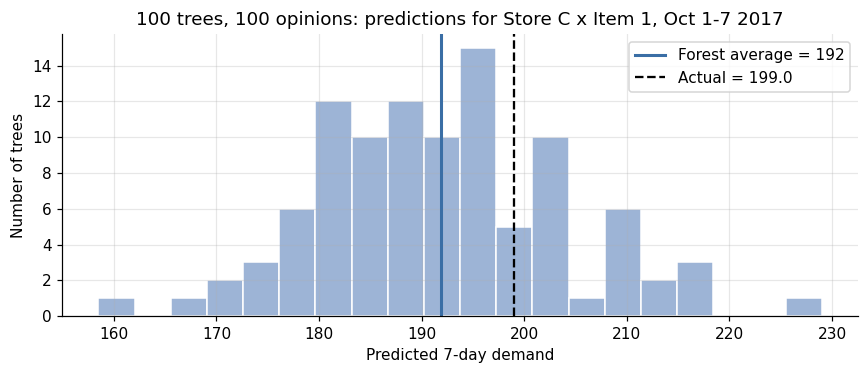

In [33]:
ex_row = test[(test["store"] == 3) & (test["item"] == 1) & (test["date"] == "2017-10-01")]
x_ex = ex_row[final_cols].to_numpy()
tree_preds = np.array([tree.predict(x_ex)[0] for tree in final_model.estimators_])

print("Store C x Item 1, forecast made on 2017-10-01 for Oct 1-7")
for i in [0, 1, 2]:
    print(f"  Tree {i + 1:3d} -> {tree_preds[i]:6.1f}")
print("  ...")
print(f"  Tree {len(tree_preds):3d} -> {tree_preds[-1]:6.1f}")
print(f"Average of {len(tree_preds)} trees  = {tree_preds.mean():.1f}")
print(f"Random Forest .predict()  = {final_model.predict(ex_row[final_cols])[0]:.1f}")
print(f"Actual demand Oct 1-7     = {ex_row[TARGET].iloc[0]}")
print(f"Last Week baseline        = {ex_row['rolling_7'].iloc[0] * 7:.0f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(tree_preds, bins=20, color="#9db4d6", edgecolor="white")
ax.axvline(tree_preds.mean(), color="#3a6ea5", lw=2, label=f"Forest average = {tree_preds.mean():.0f}")
ax.axvline(ex_row[TARGET].iloc[0], color="black", ls="--", lw=1.5, label=f"Actual = {ex_row[TARGET].iloc[0]}")
ax.set(title="100 trees, 100 opinions: predictions for Store C x Item 1, Oct 1-7 2017",
       xlabel="Predicted 7-day demand", ylabel="Number of trees")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_1_tree_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

---
# 第五阶段：Evaluation（模型评估）

训练完以后，不能只说“模型成功运行了”，一定要**量化模型到底准不准**。我们主要报告两个指标：

**MAE（Mean Absolute Error，平均绝对误差）**

$$MAE = \frac{1}{n}\sum |y - \hat{y}|$$

例如实际 80、预测 74，误差就是 6 件。如果最终 MAE = 7.2，可以理解成“**模型平均每次预测差 7.2 件**”，这非常容易向老师解释。

**RMSE（Root Mean Squared Error，均方根误差）**

$$RMSE = \sqrt{\frac{1}{n}\sum (y - \hat{y})^2}$$

RMSE 会先把误差平方，所以对**很大的错误惩罚更重**：实际 20、预测 21，问题不大；实际 20、预测 80，RMSE 会明显变大。

同时报告 MAE 和 RMSE：前者说明“平均差多少”，后者说明“有没有严重的离谱错误”。另外附上 WAPE（百分比误差）和 Bias（系统性偏高或偏低），与第三阶段保持一致。

## 5.1 用小例子看 MAE 和 RMSE 的区别

这段代码用上面的例子检查 `evaluate()` 函数，确认 MAE 和 RMSE 的计算与定义一致：
- 两次预测各差 6 件和 1 件时，MAE 和 RMSE 很接近；
- 当其中一次变成离谱的错误（实际 20、预测 80）时，RMSE 比 MAE 涨得多。

In [34]:
print("Small errors   :", evaluate([80, 20], [74, 21])[["MAE", "RMSE"]].round(2).to_dict())
print("One huge error :", evaluate([80, 20], [74, 80])[["MAE", "RMSE"]].round(2).to_dict())

Small errors   : {'MAE': 3.5, 'RMSE': 4.3}
One huge error : {'MAE': 33.0, 'RMSE': 42.64}


## 5.2 测试集（2017 年）总成绩：Random Forest vs Baseline

这段代码在 2017 年测试集上计算所有模型的指标：
- **最终模型（4.3 节选出的方案）**；
- 另外两个特征方案，仅作参考；
- 三个 baseline，以及随机波动下限。

并计算最终模型相对于 Last Week 和最强简单规则，MAE 降低了多少百分比。

In [35]:
rows = {f"{name}{' (FINAL)' if name == FINAL else ''}": evaluate(test[TARGET], p)
        for name, p in test_pred.items()}
for b in ["Last Week", "4-Week Average", "Last Year x Growth"]:
    rows[f"Baseline: {b}"] = evaluate(test[TARGET], test[f"pred_{b}"])
results = pd.DataFrame(rows).T
noise_floor = noise_floor_mae
display(results)

rf_mae = results.loc[f"{FINAL} (FINAL)", "MAE"]
lw_mae = results.loc["Baseline: Last Week", "MAE"]
ly_mae = results.loc["Baseline: Last Year x Growth", "MAE"]
print(f"Final Random Forest MAE = {rf_mae:.1f} | RMSE = {results.loc[f'{FINAL} (FINAL)', 'RMSE']:.1f}")
print(f"  vs Last Week          : MAE {lw_mae:.1f} -> {rf_mae:.1f}  ({(1 - rf_mae / lw_mae):.0%} lower)")
print(f"  vs Last Year x Growth : MAE {ly_mae:.1f} -> {rf_mae:.1f}  ({(1 - rf_mae / ly_mae):.0%} lower)")
print(f"  Noise floor (approx.) : {noise_floor:.1f}  -> RF is above it, as it should be")

,MAE,RMSE,WAPE %,Bias
RF-1 Core,22.16,29.92,5.36,-1.11
RF-2 Full base (FINAL),18.44,24.07,4.46,-0.30
RF-3 Base + EDA,18.78,24.46,4.54,6.48
Baseline: Last Week,26.91,36.87,6.51,-0.41
Baseline: 4-Week Average,31.13,42.98,7.53,-0.84
Baseline: Last Year x Growth,25.39,32.81,6.14,0.56


Final Random Forest MAE = 18.4 | RMSE = 24.1
  vs Last Week          : MAE 26.9 -> 18.4  (31% lower)
  vs Last Year x Growth : MAE 25.4 -> 18.4  (27% lower)
  Noise floor (approx.) : 15.7  -> RF is above it, as it should be


## 5.3 对比图：MAE 和 RMSE（可直接放进 PPT）

这段代码把最终 Random Forest 和三个 baseline 的 MAE、RMSE 画在一起，并用虚线标出随机波动下限。

一眼就能看出：AI 模型的柱子比所有简单规则都低，而且比它们都更接近“理论最佳”。

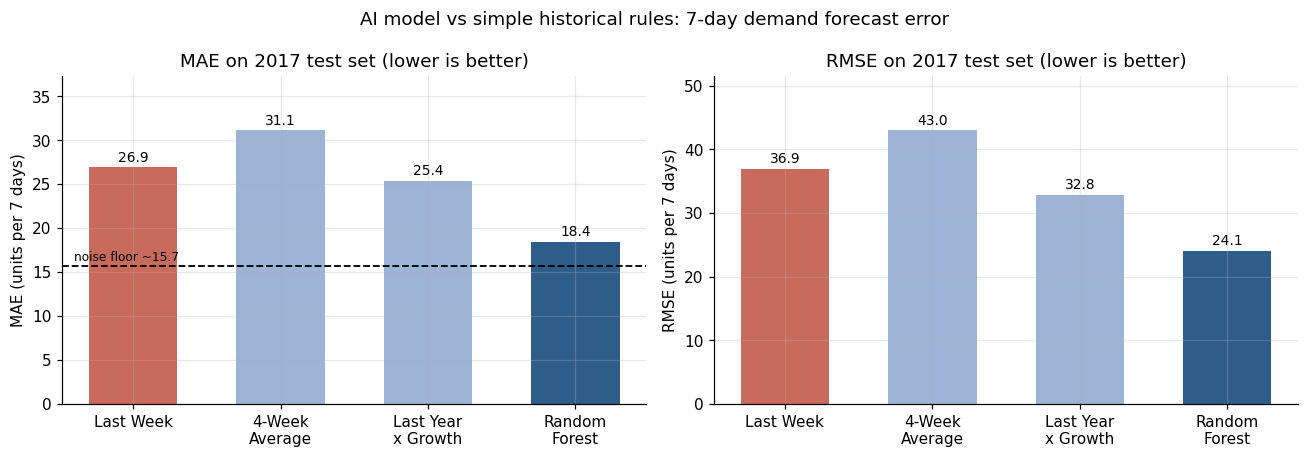

In [36]:
show = ["Baseline: Last Week", "Baseline: 4-Week Average", "Baseline: Last Year x Growth", f"{FINAL} (FINAL)"]
labels = ["Last Week", "4-Week\nAverage", "Last Year\nx Growth", "Random\nForest"]
colors = ["#c96b5c", "#9db4d6", "#9db4d6", "#2f5d8a"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    vals = results.loc[show, metric]
    bars = ax.bar(labels, vals, color=colors, width=0.6)
    ax.bar_label(bars, fmt="%.1f", fontsize=9, padding=2)
    ax.set(title=f"{metric} on 2017 test set (lower is better)", ylabel=f"{metric} (units per 7 days)",
           ylim=(0, vals.max() * 1.2))
axes[0].axhline(noise_floor, color="black", ls="--", lw=1.2)
axes[0].text(-0.4, noise_floor + 0.6, f"noise floor ~{noise_floor:.1f}", fontsize=8)
fig.suptitle("AI model vs simple historical rules: 7-day demand forecast error", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_3_model_vs_baselines.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.4 按月份看：AI 在季节转折期是否更稳？

第三阶段（3.5 节）发现，“下周 = 上周”在 **2 到 4 月（需求上升）**和 **12 月（需求下降）**错得最多。这段代码按月份比较 Random Forest 和 Last Week 的 WAPE 与 Bias，检查 AI 是否改善了这些最容易出错的时期。

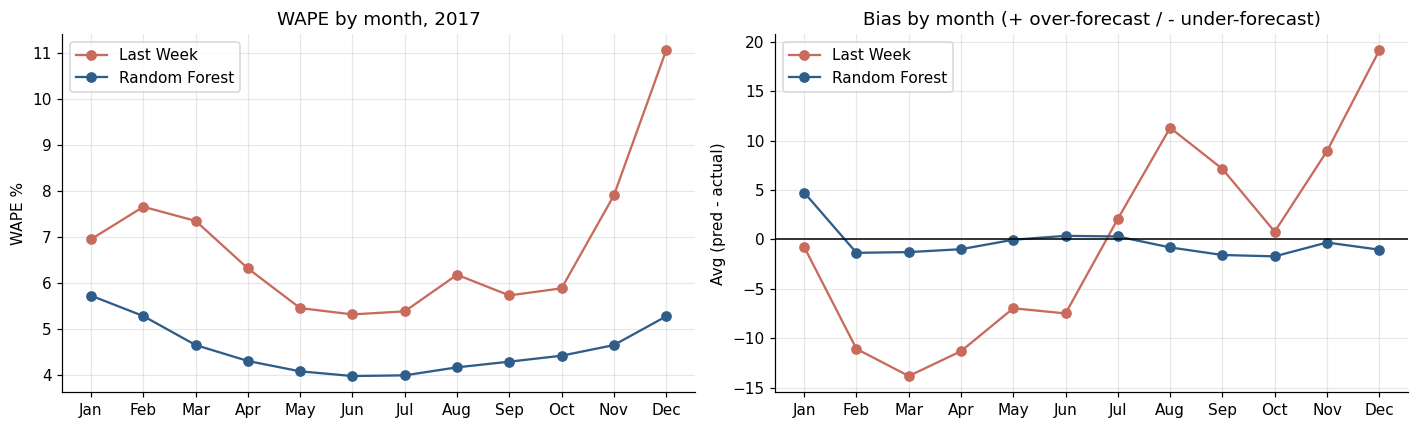

month,1,2,3,4,5,6,7,8,9,10,11,12
RF WAPE %,5.70,5.30,4.70,4.30,4.10,4.00,4.00,4.20,4.30,4.40,4.60,5.30
Last Week WAPE %,6.90,7.70,7.30,6.30,5.50,5.30,5.40,6.20,5.70,5.90,7.90,11.00
RF Bias,4.70,-1.40,-1.30,-1.00,-0.00,0.40,0.30,-0.80,-1.60,-1.70,-0.30,-1.00
Last Week Bias,-0.80,-11.10,-13.80,-11.30,-7.00,-7.50,2.10,11.30,7.10,0.80,8.90,19.10


In [37]:
test["month"] = test["date"].dt.month
def by_month(col, fn):
    return test.groupby("month").apply(lambda d: fn(d[col], d[TARGET]), include_groups=False)
wape = lambda p, y: np.sum(np.abs(p - y)) / np.sum(y) * 100
bias = lambda p, y: np.mean(p - y)

monthly = pd.DataFrame({
    "RF WAPE %": by_month("pred_RF", wape), "Last Week WAPE %": by_month("pred_Last Week", wape),
    "RF Bias": by_month("pred_RF", bias), "Last Week Bias": by_month("pred_Last Week", bias)})

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(MONTHS, monthly["Last Week WAPE %"], marker="o", color="#c96b5c", label="Last Week")
axes[0].plot(MONTHS, monthly["RF WAPE %"], marker="o", color="#2f5d8a", label="Random Forest")
axes[0].set(title="WAPE by month, 2017", ylabel="WAPE %")
axes[1].plot(MONTHS, monthly["Last Week Bias"], marker="o", color="#c96b5c", label="Last Week")
axes[1].plot(MONTHS, monthly["RF Bias"], marker="o", color="#2f5d8a", label="Random Forest")
axes[1].axhline(0, color="black", lw=1)
axes[1].set(title="Bias by month (+ over-forecast / - under-forecast)", ylabel="Avg (pred - actual)")
axes[0].legend(); axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_4_error_by_month.png", dpi=150, bbox_inches="tight")
plt.show()
display(monthly.T.round(1))

## 5.5 只看演示用的三家店（Store A / B / C）

Presentation 里的场景只有 A、B、C 三家店，对应数据中的 Store 1、2、3。这段代码检查在这三家店上，Random Forest 是否同样优于 Last Week，避免“整体平均好看，但演示用的门店不好”的情况。

In [38]:
abc_rows = {}
for s, d in test[test["store"].isin([1, 2, 3])].groupby("store"):
    name = f"Store {'ABC'[s - 1]}"
    rf, lw = evaluate(d[TARGET], d["pred_RF"]), evaluate(d[TARGET], d["pred_Last Week"])
    abc_rows[name] = {"Last Week MAE": lw["MAE"], "RF MAE": rf["MAE"],
                      "Last Week RMSE": lw["RMSE"], "RF RMSE": rf["RMSE"],
                      "MAE reduction %": (1 - rf["MAE"] / lw["MAE"]) * 100}
display(pd.DataFrame(abc_rows).T)

,Last Week MAE,RF MAE,Last Week RMSE,RF RMSE,MAE reduction %
Store A,25.28,17.51,34.32,22.59,30.75
Store B,31.89,21.97,44.14,29.09,31.10
Store C,29.15,19.74,39.96,25.49,32.29


---
# 第六阶段：Actual vs Predicted

只展示 “RMSE = 8.391” 这样的数字不够直观。把**真实需求**和**模型预测**画在同一张图上，老师一眼就能看出：**AI 到底有没有学到需求的变化？**

## 6.1 Item 1 × Store A：2017 年全年

这段代码画出 Item 1 × Store A（数据中的 Store 1）在 2017 年每一天做的预测：
- **黑线**：实际的未来 7 天需求；
- **蓝线**：Random Forest 的预测；
- **红色虚线**：Last Week baseline 的预测，作为对照。

如果蓝线紧贴黑线，并且能跟上季节的起伏，就说明模型学到了需求变化，而不只是复制上周的数字。

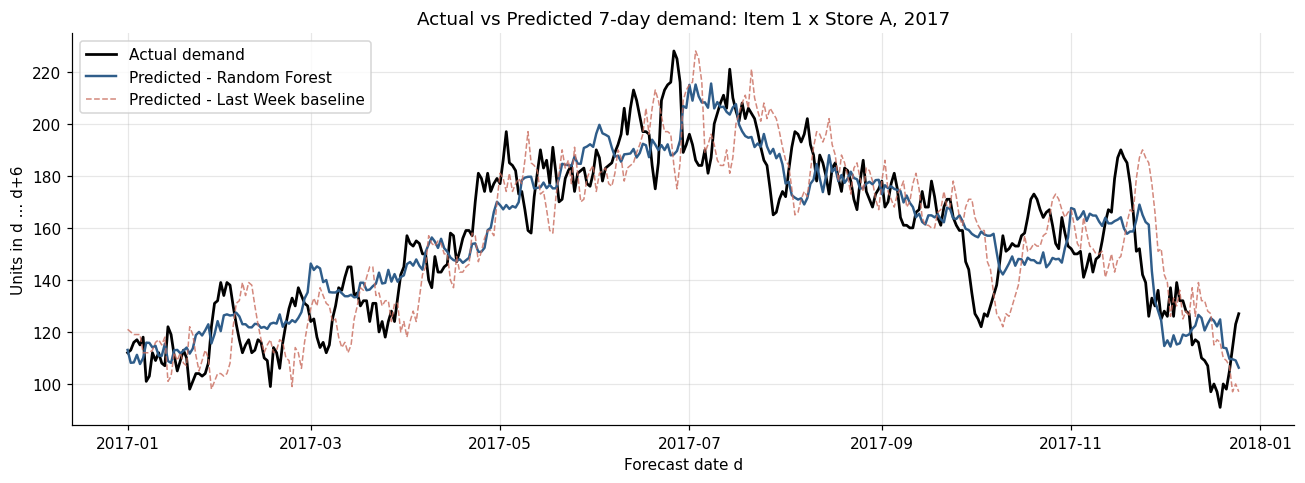

Item 1 x Store A in 2017 | Random Forest: MAE 11.8, RMSE 14.5 | Last Week: MAE 14.9, RMSE 18.7


In [39]:
STORE_A, ITEM = 1, 1
one = test[(test["store"] == STORE_A) & (test["item"] == ITEM)].set_index("date")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(one.index, one[TARGET], color="black", lw=1.8, label="Actual demand")
ax.plot(one.index, one["pred_RF"], color="#2f5d8a", lw=1.6, label="Predicted - Random Forest")
ax.plot(one.index, one["pred_Last Week"], color="#c96b5c", lw=1, ls="--", alpha=0.8,
        label="Predicted - Last Week baseline")
ax.set(title=f"Actual vs Predicted 7-day demand: Item {ITEM} x Store A, 2017",
       xlabel="Forecast date d", ylabel="Units in d ... d+6")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_5_actual_vs_predicted_item1_storeA.png", dpi=150, bbox_inches="tight")
plt.show()

m_rf, m_lw = evaluate(one[TARGET], one["pred_RF"]), evaluate(one[TARGET], one["pred_Last Week"])
print(f"Item {ITEM} x Store A in 2017 | Random Forest: MAE {m_rf['MAE']:.1f}, RMSE {m_rf['RMSE']:.1f} "
      f"| Last Week: MAE {m_lw['MAE']:.1f}, RMSE {m_lw['RMSE']:.1f}")

## 6.2 放大季节转折期：11 月到 12 月

12 月是需求从高位快速下滑的月份，也是 baseline 最容易出错的时候。这段代码放大 2017 年 11 月到 12 月，并用**所有 500 条序列的总和**来画：把所有门店和商品的实际需求、预测需求分别加总。这样随机波动会互相抵消，更容易看清系统性的差别：
- Last Week 会明显**滞后**，需求已经下降了，它还在按上周的高位预测；
- Random Forest 是否能更早跟上这个下降。

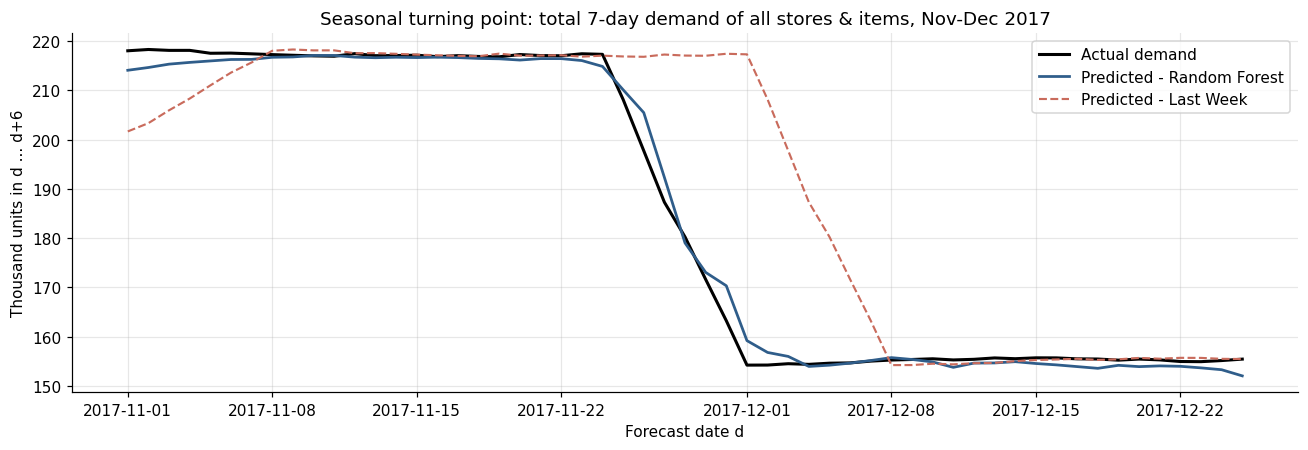

December 2017 average bias: Last Week +19.1 units, Random Forest -1.0 units


In [40]:
agg = (test[(test["date"] >= "2017-11-01")]
       .groupby("date")[[TARGET, "pred_RF", "pred_Last Week"]].sum() / 1000)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(agg.index, agg[TARGET], color="black", lw=2, label="Actual demand")
ax.plot(agg.index, agg["pred_RF"], color="#2f5d8a", lw=1.8, label="Predicted - Random Forest")
ax.plot(agg.index, agg["pred_Last Week"], color="#c96b5c", lw=1.4, ls="--", label="Predicted - Last Week")
ax.set(title="Seasonal turning point: total 7-day demand of all stores & items, Nov-Dec 2017",
       xlabel="Forecast date d", ylabel="Thousand units in d ... d+6")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_6_turning_point_nov_dec.png", dpi=150, bbox_inches="tight")
plt.show()

dec = test[test["month"] == 12]
print(f"December 2017 average bias: Last Week {np.mean(dec['pred_Last Week'] - dec[TARGET]):+.1f} units, "
      f"Random Forest {np.mean(dec['pred_RF'] - dec[TARGET]):+.1f} units")

## 6.3 全部测试样本：预测值 vs 实际值散点图

这段代码把测试集里**所有**的预测画成散点（为了画图速度，随机抽取 1 万个点）：
- 横轴是实际需求，纵轴是预测需求；
- 如果预测完全正确，点会全部落在 **45° 对角线**上；
- 点越紧贴对角线越好。左图是 Last Week，右图是 Random Forest，可以直接对比两者的分散程度。

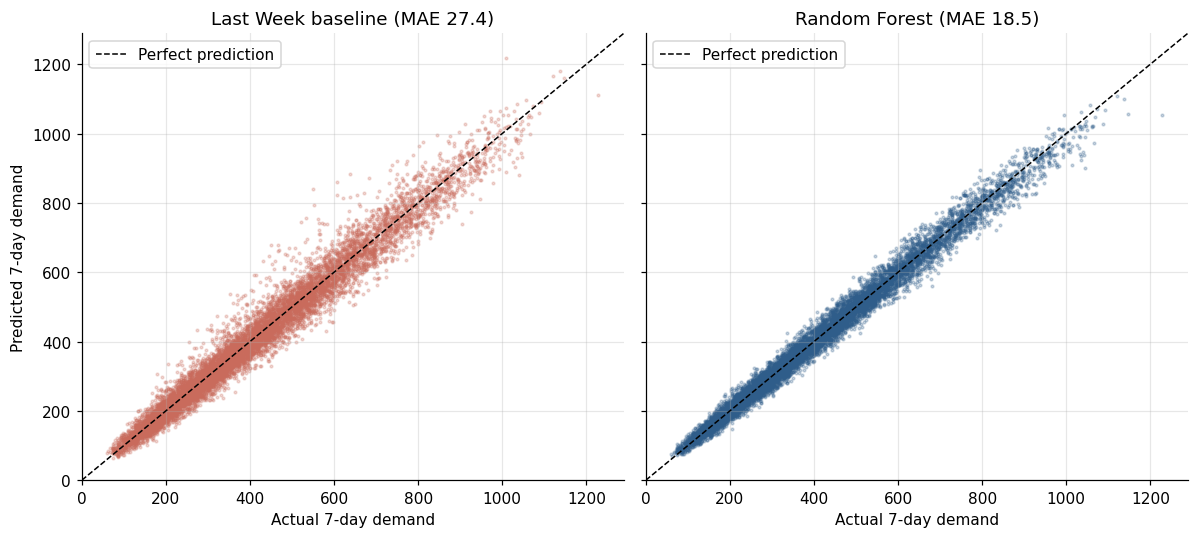

In [41]:
sample = test.sample(10_000, random_state=SEED)
lim = (0, sample[TARGET].max() * 1.05)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, col, title, color in [(axes[0], "pred_Last Week", "Last Week baseline", "#c96b5c"),
                              (axes[1], "pred_RF", "Random Forest", "#2f5d8a")]:
    ax.scatter(sample[TARGET], sample[col], s=3, alpha=0.25, color=color)
    ax.plot(lim, lim, color="black", lw=1, ls="--", label="Perfect prediction")
    mae = np.mean(np.abs(sample[col] - sample[TARGET]))
    ax.set(title=f"{title} (MAE {mae:.1f})", xlabel="Actual 7-day demand", xlim=lim, ylim=lim)
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted 7-day demand")
fig.tight_layout()
fig.savefig(FIG_DIR / "rf_7_scatter_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## 第四到六阶段小结

## 结果一览（2017 年测试集，共 179,500 次预测）

| 模型 | MAE（件 / 7 天） | RMSE | WAPE |
|---|---:|---:|---:|
| Baseline：Last Week（下周 = 上周） | 26.9 | 36.9 | 6.5% |
| Baseline：Last Year × Growth（最强简单规则） | 25.4 | 32.8 | 6.1% |
| **Random Forest（RF-2 Full base，最终模型）** | **18.4** | **24.1** | **4.5%** |
| 随机波动下限（约） | 15.7 | – | 3.8% |

**可以在 Presentation 里说的结论：**
> *“Our Random Forest predicts next-7-day demand with an average error of about 18 units, **31% lower than the ‘next week = last week’ rule** and 27% lower than the best simple rule we tested.”*

## 关键发现
1. **AI 确实优于简单规则。** 最终模型的 MAE 和 RMSE 都明显低于三个 baseline。在演示用的 Store A、B、C 三家店上，MAE 也都降低了 31% 到 32%。
2. **AI 在季节转折期的优势最大。** 12 月 Last Week 平均高估 **+19.1 件**，Random Forest 只偏差 **−1.0 件**；2 到 4 月 Last Week 低估 11 到 14 件，Random Forest 只偏差约 1 件。6.2 节的图显示，需求在 11 月底急剧下降时，Random Forest 几乎同步跟上，Last Week 晚了约一周。**这正是调拨决策最容易出错、代价也最大的时候。**
3. **模型主要依靠“近期销量水平”。** `rolling_7`、`rolling_14`、`rolling_28` 合计约占 89% 的重要性；`day_of_week`、`is_weekend` 几乎为 0，和 EDA 的判断一致。
4. **更多特征不一定更好。** RF-3 加入去年同期和同比增长特征后，验证集 MAE 只低了不到 2%，但出现了明显的系统性偏差（验证集 −6.6，测试集 +6.5）。原因是它假设“去年的增长速度会延续”，而每年的实际增速都不一样（2016 年约 8.6%，2017 年只有约 3.6%）。按照事先定好的规则，我们选了偏差更小的 RF-2。
5. **结果合理，没有泄漏迹象。** 测试集 MAE（18.4）高于随机波动下限（约 15.7），说明模型没有“偷看未来”。剩下约 2.7 件的差距，就是理论上还能改进的空间。

## 答辩时需要如实说明的局限
- 数据是 Kaggle 的公开**模拟数据**，规律比真实零售数据更规整。真实数据里有促销、缺货、天气等因素，准确度会更低。
- 这个数据集中，月与月之间的需求变化很突然（比如 12 月初直接下降）。RF-2 能提前跟上，靠的是 `week_of_year`、`day_of_month` 这类精确到天和周的日历特征；只有 `month` 的 RF-1 就做不到。真实数据里的季节变化通常更平缓。
- 模型只预测一个数字。后续可以利用 100 棵树预测值的分散程度（见 4.5 节）给出预测区间，用于 concern 部分的“显示不确定性”。

---
# 第七阶段：Hyperparameter Tuning（超参数调整）

**超参数**是训练开始之前由我们自己设定的“模型设置”，比如森林里有几棵树、每棵树能长多深。它们和模型从数据里学到的规则不同，模型不会自己调整这些设置。

| Parameter | 意义 | 调大会怎样 |
|---|---|---|
| `n_estimators` | 有多少棵树 | 预测更稳定，但训练更慢；到一定数量后几乎不再提升 |
| `max_depth` | 每棵树最多多深 | 树能学到更细的规律，但更容易**过拟合**（死记训练数据） |
| `min_samples_split` | 一个节点至少有多少数据才能继续分裂 | 树更“保守”，不容易过拟合 |
| `min_samples_leaf` | 最终的叶子节点至少有多少数据 | 每个预测基于更多样本，更平滑 |
| `max_features` | 每次分裂时随机看多少比例的变量 | 越小，树与树之间差异越大，平均后的效果可能更好；但单棵树会变弱 |

**我们的原则：不做疯狂的 Grid Search（穷举所有参数组合）。** 这个项目的重点不是把 MAE 从 7.42 调到 7.39，而是比较**几组有代表性的合理参数**，确认第四阶段的设置是否合理。

本阶段继续使用第四阶段选出的特征方案 **RF-2 Full base**（15 个基础特征），数据划分也和第四阶段相同：

| 用途 | 日期范围 |
|---|---|
| 训练（fit） | 2014-01-28 到 2015-12-25 |
| 验证（比较参数） | 2016-01-01 到 2016-12-25 |
| 最终训练 | 2014-01-28 到 2016-12-25（全部训练数据） |
| 测试（最后只用一次） | 2017-01-01 到 2017-12-25 |

## 7.1 定义 7 组候选参数

这段代码列出要比较的参数组合。每一组只改变一两个参数，这样能看清**每个参数单独起什么作用**：

| 编号 | 设置 | 想检验什么 |
|---|---|---|
| P0 | 第四阶段的设置：100 棵树，`min_samples_leaf=5`，`max_features=0.5` | 作为对照 |
| P1 | 常见的入门设置：`max_depth=15`，`min_samples_leaf=2`，使用全部特征 | 一个“普通”的起点 |
| P2 | P0 + `max_depth=10` | 限制树的深度，会不会太简单？ |
| P3 | P0 + `min_samples_leaf=20` | 叶子更大、更平滑，会不会更好？ |
| P4 | P0 + `min_samples_split=50` | 节点分裂更保守 |
| P5 | P0，但 `max_features="sqrt"`（约 4 个特征） | 每次分裂看更少的变量 |
| P6 | P0，但 300 棵树 | 树越多越好吗？ |

In [42]:
FEATURES = final_cols            # RF-2 Full base, selected in section 4.3

BASE = dict(n_estimators=100, min_samples_leaf=5, max_features=0.5)
CANDIDATES = {
    "P0 Stage-4 setting":        dict(BASE),
    "P1 Common starter":         dict(n_estimators=100, max_depth=15, min_samples_leaf=2, max_features=1.0),
    "P2 max_depth=10":           dict(BASE, max_depth=10),
    "P3 min_samples_leaf=20":    dict(BASE, min_samples_leaf=20),
    "P4 min_samples_split=50":   dict(BASE, min_samples_split=50),
    "P5 max_features=sqrt":      dict(BASE, max_features="sqrt"),
    "P6 300 trees":              dict(BASE, n_estimators=300),
}
for name, p in CANDIDATES.items():
    print(f"{name:26s} {p}")

P0 Stage-4 setting         {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.5}
P1 Common starter          {'n_estimators': 100, 'max_depth': 15, 'min_samples_leaf': 2, 'max_features': 1.0}
P2 max_depth=10            {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 10}
P3 min_samples_leaf=20     {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.5}
P4 min_samples_split=50    {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.5, 'min_samples_split': 50}
P5 max_features=sqrt       {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
P6 300 trees               {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5}


## 7.2 在验证集上比较 7 组参数

这段代码会：
- 用每组参数在 2014 到 2015 年的数据上训练模型，在 2016 年验证集上计算误差；
- 同时计算**训练集上的 MAE**。训练误差和验证误差的差距越大，说明模型越倾向于“死记”训练数据，也就是过拟合；
- 记录每组参数的训练时间。

> 这里同样**不碰 2017 年测试集**。调参也是一种“选择”，必须在验证集上完成。

训练 7 个模型大约需要 1 到 2 分钟。

In [43]:
rows = []
for name, params in CANDIDATES.items():
    t0 = time.time()
    model = RandomForestRegressor(n_jobs=-1, random_state=SEED, **params).fit(fit_part[FEATURES], fit_part[TARGET])
    secs = time.time() - t0
    val_m = evaluate(val_part[TARGET], model.predict(val_part[FEATURES]))
    train_mae = np.mean(np.abs(model.predict(fit_part[FEATURES]) - fit_part[TARGET]))
    rows.append({"setting": name, "Train MAE": train_mae, "Val MAE": val_m["MAE"], "Val RMSE": val_m["RMSE"],
                 "Val Bias": val_m["Bias"], "Train time (s)": secs})
    print(f"  {name:26s} val MAE {val_m['MAE']:6.2f} | {secs:4.0f}s")

tuning = pd.DataFrame(rows).set_index("setting")
tuning["Overfit gap"] = tuning["Val MAE"] - tuning["Train MAE"]
display(tuning.sort_values("Val MAE"))

  P0 Stage-4 setting         val MAE  19.19 |    9s


  P1 Common starter          val MAE  19.65 |   15s


  P2 max_depth=10            val MAE  20.33 |    5s


  P3 min_samples_leaf=20     val MAE  19.22 |    7s


  P4 min_samples_split=50    val MAE  19.16 |    8s


  P5 max_features=sqrt       val MAE  19.80 |    5s


  P6 300 trees               val MAE  19.15 |   28s


,Train MAE,Val MAE,Val RMSE,Val Bias,Train time (s),Overfit gap
setting,,,,,,
P6 300 trees,10.40,19.15,25.27,-0.60,27.83,8.75
P4 min_samples_split=50,14.25,19.16,25.36,-0.63,7.84,4.91
P0 Stage-4 setting,10.44,19.19,25.31,-0.64,8.70,8.75
P3 min_samples_leaf=20,14.80,19.22,25.48,-0.59,7.48,4.42
P1 Common starter,12.77,19.65,26.39,-0.86,14.92,6.88
P5 max_features=sqrt,12.59,19.80,26.32,-0.97,4.56,7.21
P2 max_depth=10,17.99,20.33,26.95,-0.52,5.01,2.33


## 7.3 选出最终参数

**选择规则（和 4.3 节的思路一致，事先定好）：**
1. 找出验证集 MAE 最低的参数组；
2. 和它相差 **1% 以内**的参数组视为“一样好”，在这些组里选**训练时间最短**的。更快的模型在实际系统里更容易每天重新训练，也更容易维护。

这段代码按规则自动选出最终参数，并打印和 P0（第四阶段设置）相比改进了多少。

In [44]:
best_mae = tuning["Val MAE"].min()
tied = tuning[tuning["Val MAE"] <= best_mae * 1.01]
CHOSEN = tied["Train time (s)"].idxmin()
p0_mae = tuning.loc["P0 Stage-4 setting", "Val MAE"]

print(f"Best validation MAE: {best_mae:.2f} ({tuning['Val MAE'].idxmin()})")
print(f"Settings within 1% of best: {list(tied.index)}")
print(f"==> Chosen: {CHOSEN}  {CANDIDATES[CHOSEN]}")
print(f"Validation MAE: P0 {p0_mae:.2f} -> chosen {tuning.loc[CHOSEN, 'Val MAE']:.2f} "
      f"({(p0_mae - tuning.loc[CHOSEN, 'Val MAE']) / p0_mae:+.1%} change)")

Best validation MAE: 19.15 (P6 300 trees)
Settings within 1% of best: ['P0 Stage-4 setting', 'P3 min_samples_leaf=20', 'P4 min_samples_split=50', 'P6 300 trees']
==> Chosen: P3 min_samples_leaf=20  {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.5}
Validation MAE: P0 19.19 -> chosen 19.22 (-0.2% change)


## 7.4 图：不同参数的验证误差和过拟合程度

这段代码画两张图：
- **左图**：每组参数的验证集 MAE。被选中的参数用深蓝色标出，虚线表示“比最佳差 1%”的范围；
- **右图**：训练 MAE 和验证 MAE 的对比。训练误差远低于验证误差，就说明过拟合。

可以直观看到：参数之间的差距其实很小，这也印证了“不必疯狂调参”。

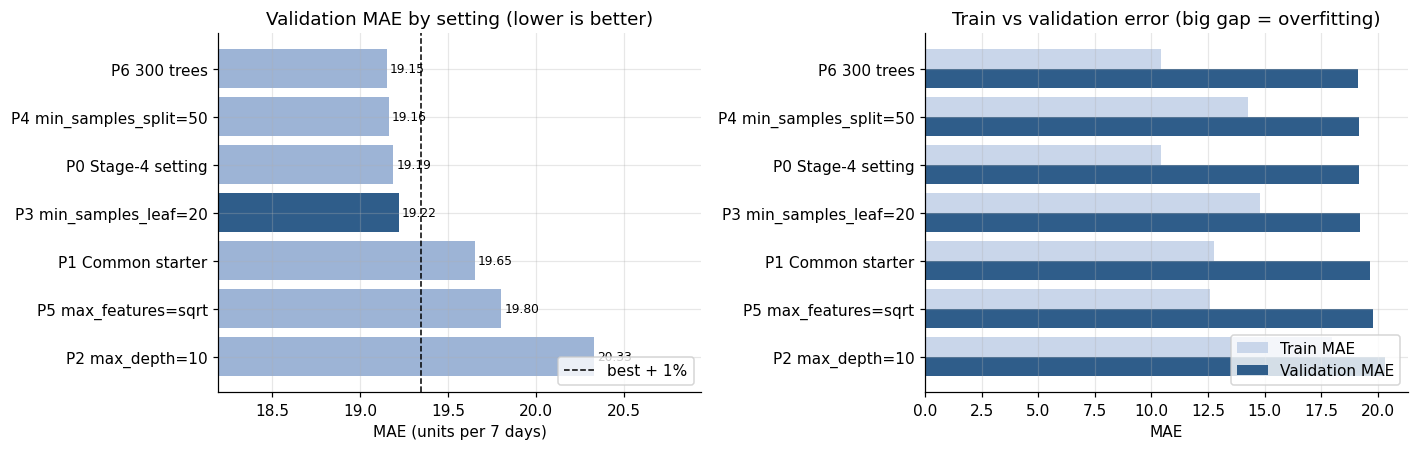

In [45]:
order = tuning.sort_values("Val MAE").index
colors = ["#2f5d8a" if n == CHOSEN else "#9db4d6" for n in order]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bars = ax.barh(order[::-1], tuning.loc[order[::-1], "Val MAE"], color=colors[::-1])
ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.axvline(best_mae * 1.01, color="black", ls="--", lw=1, label="best + 1%")
lo = tuning["Val MAE"].min() * 0.95
ax.set(title="Validation MAE by setting (lower is better)", xlabel="MAE (units per 7 days)",
       xlim=(lo, tuning["Val MAE"].max() * 1.03))
ax.legend(loc="lower right")

ax = axes[1]
y = np.arange(len(order))
ax.barh(y + 0.2, tuning.loc[order[::-1], "Train MAE"], height=0.4, color="#c9d6ea", label="Train MAE")
ax.barh(y - 0.2, tuning.loc[order[::-1], "Val MAE"], height=0.4, color="#2f5d8a", label="Validation MAE")
ax.set_yticks(y); ax.set_yticklabels(order[::-1])
ax.set(title="Train vs validation error (big gap = overfitting)", xlabel="MAE")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "tune_1_settings.png", dpi=150, bbox_inches="tight")
plt.show()

## 7.5 树越多越好吗？`n_estimators` 的学习曲线

这段代码用最终选定的参数，把树的数量从 10 棵逐步增加到 300 棵，每次都在验证集上计算 MAE。

`warm_start=True` 表示每次只在原来的森林上**增加新树**，不用从头重新训练，所以速度很快。

通常会看到：开始时误差下降很快，到某个数量后曲线变平，再增加树只会让训练更慢，几乎不会更准。

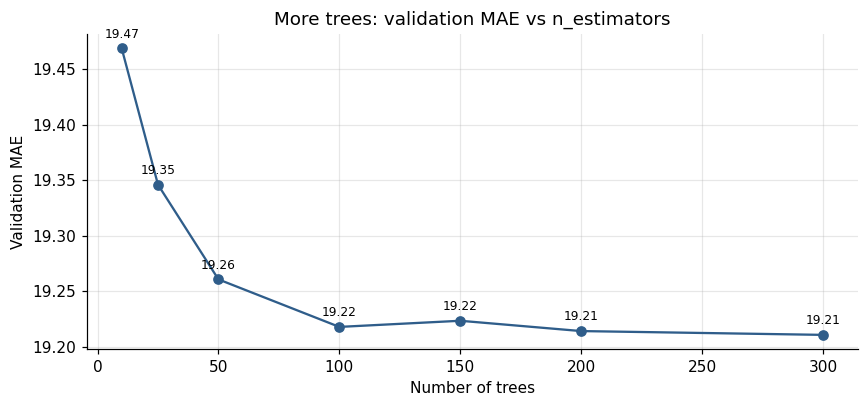

{10: np.float64(19.47), 25: np.float64(19.35), 50: np.float64(19.26), 100: np.float64(19.22), 150: np.float64(19.22), 200: np.float64(19.21), 300: np.float64(19.21)}


In [46]:
chosen_params = dict(CANDIDATES[CHOSEN])
tree_counts = [10, 25, 50, 100, 150, 200, 300]
curve = []
rf = RandomForestRegressor(n_jobs=-1, random_state=SEED, warm_start=True,
                           **{k: v for k, v in chosen_params.items() if k != "n_estimators"})
for n in tree_counts:
    rf.set_params(n_estimators=n).fit(fit_part[FEATURES], fit_part[TARGET])
    curve.append(np.mean(np.abs(rf.predict(val_part[FEATURES]) - val_part[TARGET])))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tree_counts, curve, marker="o", color="#2f5d8a")
for n, m in zip(tree_counts, curve):
    ax.annotate(f"{m:.2f}", (n, m), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(title="More trees: validation MAE vs n_estimators", xlabel="Number of trees", ylabel="Validation MAE")
fig.tight_layout()
fig.savefig(FIG_DIR / "tune_2_n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()
print({n: round(m, 2) for n, m in zip(tree_counts, curve)})

## 7.6 用最终参数重新训练，并在测试集上评估一次

这段代码会：
- 用选定的参数，在**全部训练数据**（2014-01-28 到 2016-12-25）上训练最终模型；
- 在 2017 年测试集上**只评估这一次**；
- 和第四阶段模型（P0 设置）的测试结果、Last Week baseline 放在一起比较。

In [47]:
t0 = time.time()
tuned_model = RandomForestRegressor(n_jobs=-1, random_state=SEED, **chosen_params).fit(
    train_all[FEATURES], train_all[TARGET])
print(f"Tuned model trained in {time.time() - t0:.0f}s")
test["pred_RF_tuned"] = tuned_model.predict(test[FEATURES])

compare = pd.DataFrame({
    "Baseline: Last Week":     results.loc["Baseline: Last Week"],
    "Stage 4 RF (P0 setting)": results.loc[f"{FINAL} (FINAL)"],
    f"Tuned RF ({CHOSEN.split()[0]})": evaluate(test[TARGET], test["pred_RF_tuned"]),
}).T
display(compare)
lw = compare.loc["Baseline: Last Week", "MAE"]; tuned = compare.iloc[-1]["MAE"]
print(f"Tuned RF test MAE {tuned:.2f} -> {(1 - tuned / lw):.0%} lower than Last Week")

Tuned model trained in 14s


,MAE,RMSE,WAPE %,Bias
Baseline: Last Week,26.91,36.87,6.51,-0.41
Stage 4 RF (P0 setting),18.44,24.07,4.46,-0.30
Tuned RF (P3),18.54,24.31,4.48,-0.21


Tuned RF test MAE 18.54 -> 31% lower than Last Week


---
# 第八阶段：Feature Importance（特征重要性）

Random Forest 有一个对 Presentation 非常有用的功能：**Feature Importance**。它可以告诉我们模型主要依赖哪些信息，让我们能解释模型，而不是只说“它是一个黑盒 AI”。

本阶段用两种方法计算重要性，互相印证：

| 方法 | 怎么算 | 优点 | 缺点 |
|---|---|---|---|
| **① 内置重要性（MDI）** | 训练时，每个特征在所有树的分裂中一共让误差减少了多少 | 训练完直接得到，不用额外计算 | 只反映训练集；如果几个特征很相似，功劳会被它们“平分” |
| **② 置换重要性（Permutation）** | 在测试集上把某个特征的值**随机打乱**，看 MAE 变差多少 | 用测试集计算，单位就是“件”，非常直观 | 需要额外计算 |

置换重要性的思路很好理解：如果把某一列打乱后，模型预测几乎不受影响，说明模型根本不依赖这个特征；如果打乱后误差大增，说明它非常重要。

## 8.1 方法 ①：内置重要性（MDI）

这段代码会：
- 取出最终模型的 `feature_importances_`，换算成百分比（全部加起来是 100%）；
- 把排名前 6 的特征单独列出，其余合并为 “Others”，做成一张适合放进 PPT 的表；
- 画出全部 15 个特征的重要性柱状图。

,Importance %
rolling_7,43.63
rolling_14,30.21
rolling_28,15.30
lag_1,6.14
lag_7,2.01
lag_14,0.94
Others,1.77


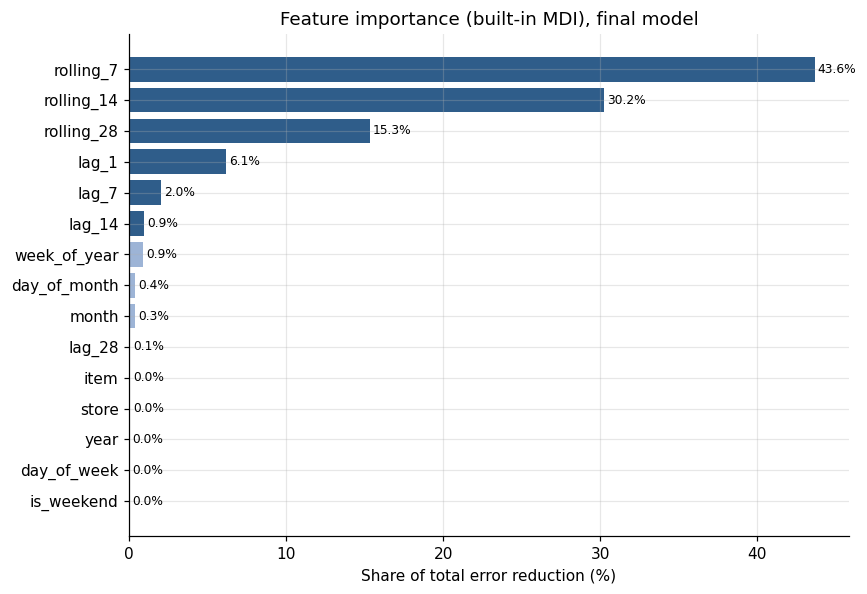

In [48]:
mdi = pd.Series(tuned_model.feature_importances_, index=FEATURES).sort_values(ascending=False) * 100

top = mdi.head(6)
mdi_table = pd.concat([top, pd.Series({"Others": mdi.iloc[6:].sum()})]).to_frame("Importance %")
display(mdi_table)

fig, ax = plt.subplots(figsize=(8, 5.5))
s = mdi.sort_values()
bars = ax.barh(s.index, s.values, color=["#2f5d8a" if v >= top.min() else "#9db4d6" for v in s.values])
ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set(title="Feature importance (built-in MDI), final model", xlabel="Share of total error reduction (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fi_1_mdi.png", dpi=150, bbox_inches="tight")
plt.show()

## 8.2 方法 ②：置换重要性（在测试集上）

这段代码会：
- 从 2017 年测试集随机抽取 30,000 行，先计算正常情况下的 MAE；
- 每次把**一个特征**的值随机打乱，重新预测并计算 MAE，看 MAE **增加了多少件**；
- 每个特征重复打乱 3 次取平均，减少随机性的影响。

结果的单位是“件”，可以直接这样解读：*“如果模型拿不到 rolling_7 这个信息，平均每次预测会多错 X 件。”*

计算大约需要 1 分钟。

MAE with all features intact: 18.63


,MAE increase when shuffled (units)
rolling_7,64.86
rolling_14,56.41
rolling_28,38.46
week_of_year,9.37
day_of_month,2.83
month,2.72
lag_1,0.53
lag_7,0.09
lag_28,0.05
lag_14,0.04


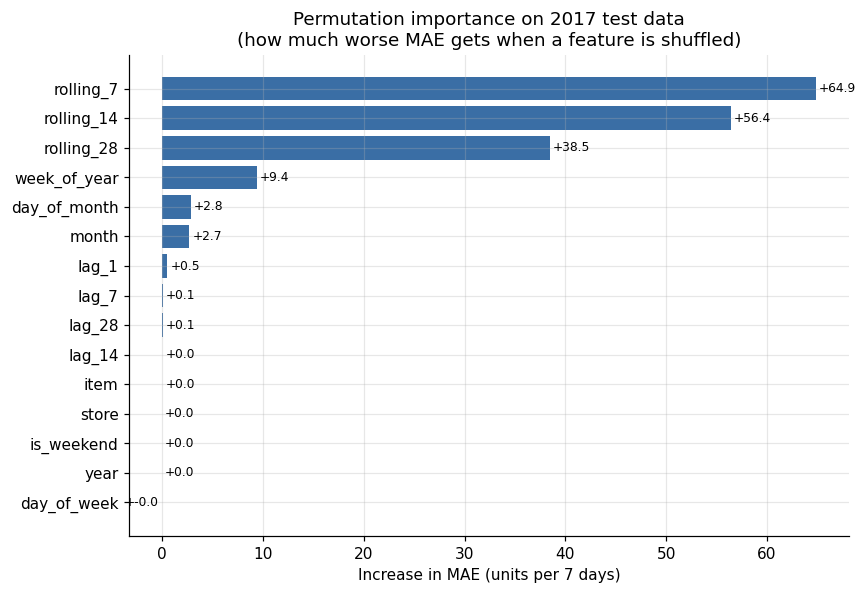

In [49]:
rng = np.random.default_rng(SEED)
sample = test.sample(30_000, random_state=SEED)
X_s, y_s = sample[FEATURES].copy(), sample[TARGET].to_numpy()
base_mae = np.mean(np.abs(tuned_model.predict(X_s) - y_s))

def permuted_mae(cols, repeats=3):
    """Shuffle the given column(s) together and return the average MAE."""
    out = []
    for _ in range(repeats):
        X_p = X_s.copy()
        idx = rng.permutation(len(X_p))
        X_p[cols] = X_p[cols].to_numpy()[idx]
        out.append(np.mean(np.abs(tuned_model.predict(X_p) - y_s)))
    return np.mean(out)

perm = pd.Series({f: permuted_mae([f]) - base_mae for f in FEATURES}).sort_values(ascending=False)
print(f"MAE with all features intact: {base_mae:.2f}")
display(perm.to_frame("MAE increase when shuffled (units)"))

fig, ax = plt.subplots(figsize=(8, 5.5))
s = perm.sort_values()
bars = ax.barh(s.index, s.values, color="#3a6ea5")
ax.bar_label(bars, fmt="+%.1f", fontsize=8, padding=2)
ax.set(title="Permutation importance on 2017 test data\n(how much worse MAE gets when a feature is shuffled)",
       xlabel="Increase in MAE (units per 7 days)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fi_2_permutation.png", dpi=150, bbox_inches="tight")
plt.show()

## 8.3 按“信息类型”分组：更适合 Presentation 的讲法

单个特征之间往往高度相关，比如 `rolling_7`、`rolling_14`、`rolling_28` 都在描述“最近卖得怎么样”。只打乱其中一个时，模型还能从另外两个那里拿到差不多的信息，所以单个特征的置换重要性会**低估**这一类信息的真实作用。

更好的做法是把特征按**业务含义**分成 5 组，每次把**整组一起打乱**：

| 信息类型 | 包含的特征 | 业务含义 |
|---|---|---|
| Recent sales level | `rolling_7`、`rolling_14`、`rolling_28` | 最近几周平均卖多少 |
| Recent daily sales | `lag_1`、`lag_7`、`lag_14`、`lag_28` | 最近某几天具体卖了多少 |
| Season & calendar | `year`、`month`、`week_of_year`、`day_of_month` | 现在处在一年中的什么时候 |
| Weekday | `day_of_week`、`is_weekend` | 预测窗口从星期几开始 |
| Store & item | `store`、`item` | 哪家店、哪个商品 |

这段代码计算每组信息被打乱后 MAE 增加多少，并画成图。这张图最适合放进 PPT，因为老师和同学不需要理解每个特征名，也能看懂。

,MAE increase when group is shuffled (units)
Recent sales level,210.40
Season & calendar,16.95
Recent daily sales,1.38
Store & item,0.02
Weekday,0.00


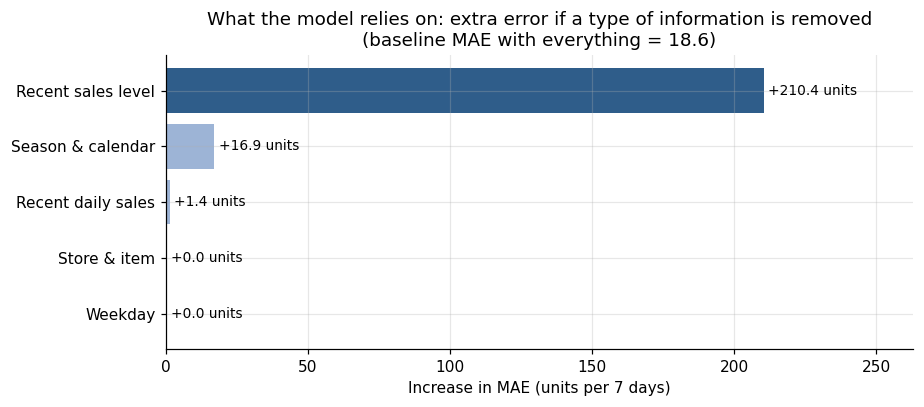

In [50]:
GROUPS = {
    "Recent sales level":  ["rolling_7", "rolling_14", "rolling_28"],
    "Recent daily sales":  ["lag_1", "lag_7", "lag_14", "lag_28"],
    "Season & calendar":   ["year", "month", "week_of_year", "day_of_month"],
    "Weekday":             ["day_of_week", "is_weekend"],
    "Store & item":        ["store", "item"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)

group_imp = pd.Series({g: permuted_mae(cols) - base_mae for g, cols in GROUPS.items()}).sort_values()
display(group_imp.sort_values(ascending=False).to_frame("MAE increase when group is shuffled (units)"))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bars = ax.barh(group_imp.index, group_imp.values,
               color=["#2f5d8a" if v == group_imp.max() else "#9db4d6" for v in group_imp.values])
ax.bar_label(bars, labels=[f"+{v:.1f} units" for v in group_imp.values], fontsize=9, padding=3)
ax.set(title=f"What the model relies on: extra error if a type of information is removed\n"
             f"(baseline MAE with everything = {base_mae:.1f})",
       xlabel="Increase in MAE (units per 7 days)", xlim=(0, group_imp.max() * 1.25))
fig.tight_layout()
fig.savefig(FIG_DIR / "fi_3_grouped_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 第七、八阶段小结

### 第七阶段：Hyperparameter Tuning

| 结果 | 数字 |
|---|---|
| 7 组参数的验证集 MAE 范围 | 19.15 到 20.33，最好和最差只差约 6% |
| 与最佳相差 1% 以内的参数组 | P0、P3、P4、P6 |
| 最终选择 | **P3**：100 棵树，`min_samples_leaf=20`，`max_features=0.5`（四组里训练最快） |
| 测试集 MAE | 调参后 18.54，第四阶段 18.44，**基本没有差别**；仍然比 Last Week 低 31% |

**结论：**
1. **调参几乎没有带来提升**，说明第四阶段的设置本来就合理。这正好印证“不需要疯狂 Grid Search”。模型的提升主要来自**好的特征**，而不是参数。
2. **限制树的深度反而更差**：`max_depth=10` 的验证 MAE 是 20.33，是 7 组中最差的。树太浅，学不到足够细的规律（欠拟合）。
3. **树的数量超过约 100 棵后基本不再提升**：10 棵树 19.47，100 棵树 19.22，300 棵树 19.21。所以 300 棵树只是让训练慢 3 倍，没有实际好处。
4. 选中的 P3 叶子更大，**过拟合程度更低**：训练误差和验证误差的差距从 8.8 降到 4.4，而准确度几乎一样。更稳定、更简单的模型，在实际系统里更值得信赖。

### 第八阶段：Feature Importance

**两种方法的结论一致：近期销量水平最重要，其次是季节和日历。**

| 信息类型 | 打乱后 MAE 增加 | 含义 |
|---|---:|---|
| **Recent sales level**（rolling_7/14/28） | **+210 件** | 决定“大概卖多少”。没有它，模型完全不知道这个商品、这家店的销量规模 |
| **Season & calendar**（month、week_of_year 等） | **+17 件** | 决定“需求什么时候会变”，这就是模型在季节转折期胜过 Last Week 的原因 |
| Recent daily sales（lag_k） | +1.4 件 | 单日销量随机波动大，和滚动平均重复，作用很小 |
| Store & item | ≈ 0 | 门店和商品的规模已经体现在近期销量里，不需要再单独看编号 |
| Weekday | ≈ 0 | 7 天总和已经抵消了星期效应，和 EDA 的判断一致 |

**和参考示例不同的地方（答辩时值得主动说明）：** 示例里 `day_of_week` 占 6%、`store` 占 12%，但在我们的模型里这两项都接近 0。原因有两个：一是我们预测的是 7 天总和，星期效应已经抵消；二是门店之间的差异已经包含在近期销量里。这说明模型学到的规律和 EDA 的分析是一致的，**模型是可以解释的**。

**Presentation 里可以用的一句话：**
> *“Recent sales patterns were by far the strongest predictor of next week's demand, and seasonal calendar information explained when demand would change. Day of week and store ID added almost nothing once recent sales were known.”*

---
# 第九阶段：最终训练模型（Final model fitting）

到这里，我们已经完成了：

| 步骤 | 状态 | 在哪里完成 |
|---|---|---|
| Baseline | ✅ | 第三阶段 |
| Validation（用 2016 年选择特征和参数） | ✅ | 4.3、7.3 节 |
| Test（用 2017 年评估，MAE 比 Last Week 低 31%） | ✅ | 第五阶段、7.6 节 |
| 参数确定（100 棵树，`min_samples_leaf=20`，`max_features=0.5`） | ✅ | 第七阶段 |

之后就不需要再保留验证集和测试集了。验证集和测试集的作用是**帮我们做选择、检验效果**；选择做完以后，应该把**全部数据（2013–2017）**都拿来训练最终模型。数据越多、越新，模型学到的规律就越完整，尤其是 2017 年这一段最新的销量水平。然后用它预测真正的未来：**2018 年**。

这就是标准机器学习流程里的 **Final model fitting**。

## 关于“预测 2018 年”，需要先说清楚两件事
1. **我们只能真正预测 2018 年的第一周（2018-01-01 到 01-07）。** 模型的特征需要“昨天、7 天前、最近 7/14/28 天”的实际销量。站在 2018-01-01 早上，这些数据都在 2017 年，是已知的；但要预测 1 月 8 日以后，就需要 1 月 1 日到 7 日的实际销量，而数据集里没有 2018 年的销量。这和真实系统的工作方式一样：**每天早上拿到最新的销量，重新预测一次未来 7 天**。
2. **2018 年没有答案可以对照。** Kaggle 的 `test.csv` 只有日期、门店和商品，没有销量，所以无法计算 2018 年的误差。模型的准确度已经在 2017 年测试集上量化过了。本阶段的“测试”是确认**最终训练流程本身正确、预测结果合理**（见 9.2、9.4、9.8 节）。

## 9.1 把特征工程写成一个函数

这段代码把第四阶段的特征计算步骤整理成一个函数 `build_features()`。输入原始销量表，输出带有 15 个基础特征和目标 `target_7d` 的表。定义和第二阶段**完全一样**：
- 特征只用 d-1 及以前的销量；
- 目标是 d 到 d+6 的销量总和。

写成函数的好处：训练和预测 2018 年时**用的是同一套代码**，不会出现“训练时这样算、预测时那样算”的错误。这在真实系统里非常重要。

同时准备最终训练要用的东西：
- `raw`：只保留原始的 4 列（日期、门店、商品、销量）；
- `PARAMS`：第七阶段选定的参数；`FEATURES`：第四阶段选定的 15 个基础特征。

> 最终模型只用基础特征，最多往前看 28 天，所以 2013 年的数据也能用来训练。第二阶段为了扩展特征丢掉了 2013 年，所以这里要从原始数据重新生成特征。

In [51]:
raw = df[["date", "store", "item", "sales"]].copy()
PARAMS = chosen_params
print(f"Final parameters: {PARAMS}")
print(f"Features ({len(FEATURES)}): {FEATURES}")

def build_features(sales: pd.DataFrame) -> pd.DataFrame:
    """Turn raw (date, store, item, sales) rows into the 15 base features + target_7d."""
    df = sales.sort_values(["store", "item", "date"]).reset_index(drop=True)
    g = df.groupby(["store", "item"])["sales"]

    df[TARGET] = g.transform(lambda s: s.rolling(HORIZON).sum().shift(-(HORIZON - 1)))
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_month"] = df["date"].dt.day
    df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
    for k in [1, 7, 14, 28]:
        df[f"lag_{k}"] = g.shift(k)
    for w in [7, 14, 28]:
        df[f"rolling_{w}"] = g.transform(lambda s, w=w: s.shift(1).rolling(w).mean())
    return df

t0 = time.time()
full = build_features(raw)
print(f"Built features for {len(full):,} rows in {time.time() - t0:.0f}s")

Final parameters: {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.5}
Features (15): ['store', 'item', 'year', 'month', 'day_of_week', 'day_of_month', 'week_of_year', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_7', 'rolling_14', 'rolling_28']


Built features for 913,000 rows in 0s


## 9.2 测试 ①：新函数算出的特征，和第二阶段的特征完全一致吗？

这段代码把 `build_features()` 的结果和第二阶段生成的特征表 `feat` 按“日期 × 门店 × 商品”对齐，逐列比较 15 个特征和目标。

全部一致，才能说明最终模型用的特征，和我们之前验证、测试过的是同一套。如果有任何差异，代码会报错并停止运行。

In [52]:
old = feat
merged = old.merge(full, on=["date", "store", "item"], suffixes=("_old", "_new"))
for col in [c for c in FEATURES if c not in ("store", "item")] + [TARGET]:   # store/item are the join keys
    assert np.allclose(merged[f"{col}_old"], merged[f"{col}_new"]), f"Mismatch in {col}"
print(f"PASSED: {len(merged):,} rows x {len(FEATURES) + 1} columns are identical to stage 2")

PASSED: 711,000 rows x 16 columns are identical to stage 2


## 9.3 准备最终训练数据：2013–2017 全部可用的行

这段代码会：
- 去掉特征或目标为空的行：每条序列开头 28 天没有足够的历史，最后 6 天没有完整的未来 7 天；
- 得到最终训练集：日期 d 从 **2013-01-29 到 2017-12-25**，目标窗口最晚到 2017-12-31，**用到了数据集里的每一天**；
- 和之前的训练集（2014-01-28 到 2016-12-25）比较，看最终模型多用了多少数据。

In [53]:
final_train = full.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Final training rows: {len(final_train):,} "
      f"({final_train['date'].min().date()} to {final_train['date'].max().date()})")
print(f"Previous training rows (stages 4/7): {(old['split'] == 'train').sum():,} "
      f"-> {len(final_train) / (old['split'] == 'train').sum():.2f}x more data")

Final training rows: 896,000 (2013-01-29 to 2017-12-25)
Previous training rows (stages 4/7): 531,500 -> 1.69x more data


## 9.4 测试 ②：最终训练流程的“彩排”

在用全部数据训练之前，先用**一模一样的流程**往回彩排一次，确认这个流程真的能做出好的预测：
- 假装今天是 **2017-01-01**：只用 2017-01-01 以前能知道的数据（目标窗口不超过 2016-12-31）训练模型；
- 预测 2017-01-01 到 01-07 的需求，共 500 个“门店 × 商品”组合；
- 这一周的真实销量是已知的，所以可以计算误差，并和 Last Week baseline 比较。

这和 2018 年的情况完全相同：用截至昨天的全部历史，训练一次，预测下一周。唯一的区别是 2017 年第一周有答案可以对照。

In [54]:
def fit_final_model(train_rows):
    return RandomForestRegressor(n_jobs=-1, random_state=SEED, **PARAMS).fit(
        train_rows[FEATURES], train_rows[TARGET])

rehearsal_day = pd.Timestamp("2017-01-01")
reh_train = final_train[final_train["date"] <= rehearsal_day - pd.Timedelta(days=HORIZON)]
reh_rows = full[full["date"] == rehearsal_day]

t0 = time.time()
reh_model = fit_final_model(reh_train)
reh_pred = reh_model.predict(reh_rows[FEATURES])
lw_pred = reh_rows["rolling_7"] * 7
mae_rf = np.mean(np.abs(reh_pred - reh_rows[TARGET]))
mae_lw = np.mean(np.abs(lw_pred - reh_rows[TARGET]))
print(f"Rehearsal: trained on {len(reh_train):,} rows (up to {reh_train['date'].max().date()}) in {time.time() - t0:.0f}s")
print(f"Forecast for {rehearsal_day.date()} ... {(rehearsal_day + pd.Timedelta(days=6)).date()}, {len(reh_rows)} store-items:")
print(f"  Random Forest MAE = {mae_rf:.1f} units | Last Week MAE = {mae_lw:.1f} units "
      f"| {(1 - mae_rf / mae_lw):.0%} lower")

Rehearsal: trained on 713,500 rows (up to 2016-12-25) in 20s
Forecast for 2017-01-01 ... 2017-01-07, 500 store-items:
  Random Forest MAE = 17.3 units | Last Week MAE = 23.0 units | 25% lower


## 9.5 正式训练最终模型

彩排通过后，这段代码用**全部数据（2013-01-29 到 2017-12-25）**和最终参数，正式训练 ReturnRoute 的 Random Forest。

> 模型没有保存成文件：100 棵树的文件有几百 MB，而重新训练只需要几十秒。真实系统也通常每天或每周用最新数据重新训练一次。

In [55]:
t0 = time.time()
final_model = fit_final_model(final_train)
print(f"Final model trained on {len(final_train):,} rows in {time.time() - t0:.0f}s")
print(final_model)

Final model trained on 896,000 rows in 27s
RandomForestRegressor(max_features=0.5, min_samples_leaf=20, n_jobs=-1,
                      random_state=42)


## 9.6 准备 2018-01-01 这一天的输入特征

这段代码模拟 **2018 年 1 月 1 日早上**系统要做的事：
- 在原始数据后面，为 500 个“门店 × 商品”组合各加一行 `date = 2018-01-01`。这一天的销量还不知道，所以设为空值；
- 用**同一个** `build_features()` 计算这一天的特征。“昨天”就是 2017-12-31，“前 7 天平均”就是 2017-12-25 到 31 的平均，以此类推；
- 检查 15 个特征全部有值。目标值为空是正常的，因为未来 7 天还没发生。

> 注意：`year = 2018` 是模型训练时没见过的值。Random Forest 会把它当作和 2017 年一样处理（树模型不能外推）。第八阶段的特征重要性显示 `year` 的作用几乎为 0，所以这对预测基本没有影响。

In [56]:
FORECAST_DAY = pd.Timestamp("2018-01-01")
pairs = raw[["store", "item"]].drop_duplicates()
new_rows = pairs.assign(date=FORECAST_DAY, sales=np.nan)
with_today = build_features(pd.concat([raw, new_rows], ignore_index=True))
X_2018 = with_today[with_today["date"] == FORECAST_DAY].reset_index(drop=True)

assert len(X_2018) == 500
assert X_2018[FEATURES].notna().all().all(), "Some features are missing!"
print(f"Input rows for {FORECAST_DAY.date()}: {len(X_2018)} | all {len(FEATURES)} features present: True")
print(f"Target known? {X_2018[TARGET].notna().any()}  (as expected: the future has not happened yet)")
X_2018.loc[X_2018["store"].isin([1, 2, 3]) & (X_2018["item"] == 1), ["date"] + FEATURES]

Input rows for 2018-01-01: 500 | all 15 features present: True
Target known? False  (as expected: the future has not happened yet)


,date,store,item,year,month,day_of_week,day_of_month,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_7,rolling_14,rolling_28
0,2018-01-01,1,1,2018,1,0,1,1,0,23.00,13.00,19.00,7.00,18.14,16.00,16.68
50,2018-01-01,2,1,2018,1,0,1,1,0,31.00,18.00,20.00,10.00,22.29,21.86,22.32
100,2018-01-01,3,1,2018,1,0,1,1,0,19.00,13.00,21.00,17.00,19.00,21.57,22.61


## 9.7 预测 2018 年第一周的需求，并给出预测范围

这段代码会：
- 用最终模型预测 500 个“门店 × 商品”组合在 **2018-01-01 到 01-07** 的需求；
- 同时取出 100 棵树各自的预测，用它们的第 10 和第 90 百分位作为**预测范围（P10–P90）**。树之间的意见越不一致，范围越宽，说明这次预测越不确定。这对应 ReturnRoute concern 部分的“显示不确定性”。

> 这个范围反映的是 100 棵树之间的分歧，是一个粗略的指标，并不是严格的统计置信区间。

In [57]:
X = X_2018[FEATURES].to_numpy()
tree_preds = np.stack([t.predict(X) for t in final_model.estimators_])     # shape: (100 trees, 500 rows)

forecast = X_2018[["store", "item"]].copy()
forecast["forecast_start"] = FORECAST_DAY.date()
forecast["predicted_7d_demand"] = final_model.predict(X_2018[FEATURES])
forecast["range_low_P10"] = np.percentile(tree_preds, 10, axis=0)
forecast["range_high_P90"] = np.percentile(tree_preds, 90, axis=0)
forecast["last_week_actual"] = X_2018["rolling_7"] * 7

assert np.allclose(tree_preds.mean(axis=0), forecast["predicted_7d_demand"])
print(f"Forecast made for {len(forecast)} store-items. Total predicted demand: "
      f"{forecast['predicted_7d_demand'].sum():,.0f} units")
forecast.head()

Forecast made for 500 store-items. Total predicted demand: 153,207 units


,store,item,forecast_start,predicted_7d_demand,range_low_P10,range_high_P90,last_week_actual
0,1,1,2018-01-01,112.93,105.73,122.64,127.00
1,1,2,2018-01-01,321.58,304.49,343.14,358.00
2,1,3,2018-01-01,185.59,173.84,196.96,185.00
3,1,4,2018-01-01,107.93,100.44,115.34,121.00
4,1,5,2018-01-01,95.00,88.76,104.36,99.00


## 9.8 测试 ③：2018 年的预测合理吗？

没有 2018 年的真实销量，但可以检查预测是否**合乎常理**。合理的范围直接从**历史上每年第一周的实际情况**算出来，不靠主观猜测。这段代码做 4 项检查：

| 检查 | 期望 |
|---|---|
| 没有空值，也没有负数 | 需求不可能是负数 |
| 第一周 ÷ 上一周（12/25–12/31） | 落在 2014–2017 年历史比例的范围内 |
| 第一周 ÷ 去年第一周 | 落在 2014–2017 年历史同比增长的范围内，并且各“门店 × 商品”的规模高度相关 |
| 门店之间的规模排序 | 和历史基本一致（Spearman 等级相关系数接近 1）。历史上 Store 4 和 9、Store 5 和 6 的销量几乎一样，它们之间互换位置属于正常情况 |

In [58]:
assert forecast["predicted_7d_demand"].notna().all() and (forecast["predicted_7d_demand"] > 0).all()
print("Check 1 PASSED: no missing or negative forecasts")

# Historical behaviour of week 1 (Jan 1-7) in 2014-2017, using total sales of all stores & items
daily_total = raw.groupby("date")["sales"].sum()
hist = pd.DataFrame({y: {
    "week1 / last week": daily_total[f"{y}-01-01":f"{y}-01-07"].sum() / daily_total[f"{y-1}-12-25":f"{y-1}-12-31"].sum(),
    "week1 / last year's week1": daily_total[f"{y}-01-01":f"{y}-01-07"].sum() / daily_total[f"{y-1}-01-01":f"{y-1}-01-07"].sum()}
    for y in [2014, 2015, 2016, 2017]}).T
display(hist.map(lambda v: f"{v:.3f}"))

fc = forecast.set_index(["store", "item"])
ly = raw[(raw["date"] >= "2017-01-01") & (raw["date"] <= "2017-01-07")].groupby(["store", "item"])["sales"].sum()
ratio_lw = fc["predicted_7d_demand"].sum() / fc["last_week_actual"].sum()
ratio_ly = fc["predicted_7d_demand"].sum() / ly.sum()
corr_ly = np.corrcoef(fc["predicted_7d_demand"], ly.loc[fc.index])[0, 1]
for label, value, col in [("Check 2: forecast / last week", ratio_lw, "week1 / last week"),
                          ("Check 3: forecast / last year's week 1", ratio_ly, "week1 / last year's week1")]:
    lo, hi = hist[col].min(), hist[col].max()
    print(f"{label:40s} = {value:.3f} | historical range {lo:.3f}-{hi:.3f} | "
          f"{'PASSED' if lo <= value <= hi else 'OUTSIDE RANGE'}")
print(f"{'         correlation with last year, by store-item':40s} = {corr_ly:.3f}")

store_fc = forecast.groupby("store")["predicted_7d_demand"].sum()
store_hist = raw.groupby("store")["sales"].sum()
spearman = store_fc.rank().corr(store_hist.rank())
print(f"Check 4: store size ranking, Spearman correlation with history = {spearman:.3f} "
      f"| largest: Store {store_fc.idxmax()} (history: Store {store_hist.idxmax()}), "
      f"smallest: Store {store_fc.idxmin()} (history: Store {store_hist.idxmin()})")

Check 1 PASSED: no missing or negative forecasts


,week1 / last week,week1 / last year's week1
2014,1.040,1.155
2015,0.939,1.042
2016,0.973,1.085
2017,0.946,1.044


Check 2: forecast / last week            = 0.985 | historical range 0.939-1.040 | PASSED
Check 3: forecast / last year's week 1   = 1.093 | historical range 1.042-1.155 | PASSED
         correlation with last year, by store-item = 0.985
Check 4: store size ranking, Spearman correlation with history = 0.988 | largest: Store 2 (history: Store 2), smallest: Store 7 (history: Store 7)


## 9.9 最终输出：ReturnRoute 需求预测表

这段代码输出 AI 模型的最终结果，也就是 ReturnRoute 系统每天早上拿到的“需求预测表”。这里只显示 Presentation 演示用的三家店（A / B / C = 数据中的 Store 1 / 2 / 3），以 Item 1 为例：

| 列 | 含义 |
|---|---|
| Predicted 7-day demand | Random Forest 预测的未来 7 天需求 |
| Range (P10–P90) | 100 棵树预测的分布范围 |
| Last week actual | 上一周的实际销量，作为参考 |

> PPT 里可以把 Item 1 称为演示商品，例如 “T-shirt M”。但要在脚注说明数据来自公开的 Kaggle 数据集，商品名只是演示用的标签。

In [59]:
DEMO_ITEM = 1
demo = forecast[forecast["store"].isin(STORE_NAME) & (forecast["item"] == DEMO_ITEM)].copy()
demo["Store"] = demo["store"].map(STORE_NAME)
demo["Item"] = f"Item {DEMO_ITEM}"
demo_table = demo[["Store", "Item", "predicted_7d_demand", "range_low_P10", "range_high_P90", "last_week_actual"]]
demo_table.columns = ["Store", "Item", "Predicted 7-day demand", "Range low (P10)", "Range high (P90)",
                      "Last week actual"]
display(demo_table.set_index("Store").round(0))

,Item,Predicted 7-day demand,Range low (P10),Range high (P90),Last week actual
Store,,,,,
A,Item 1,113.00,106.00,123.00,127.00
B,Item 1,148.00,139.00,158.00,156.00
C,Item 1,154.00,142.00,165.00,133.00


## 9.10 图：最近 8 周的实际需求 + 2018 年第一周的预测

这段代码为 Store A、B、C 的 Item 1 各画一张小图：
- **灰色柱子**：2017 年最后 8 周每周的实际销量；
- **蓝色柱子和误差线**：2018 年第一周的预测值，以及 P10–P90 范围。

这张图可以放进 PPT，让观众直观看到：模型的预测接上了最近的需求水平，同时给出了不确定的范围。

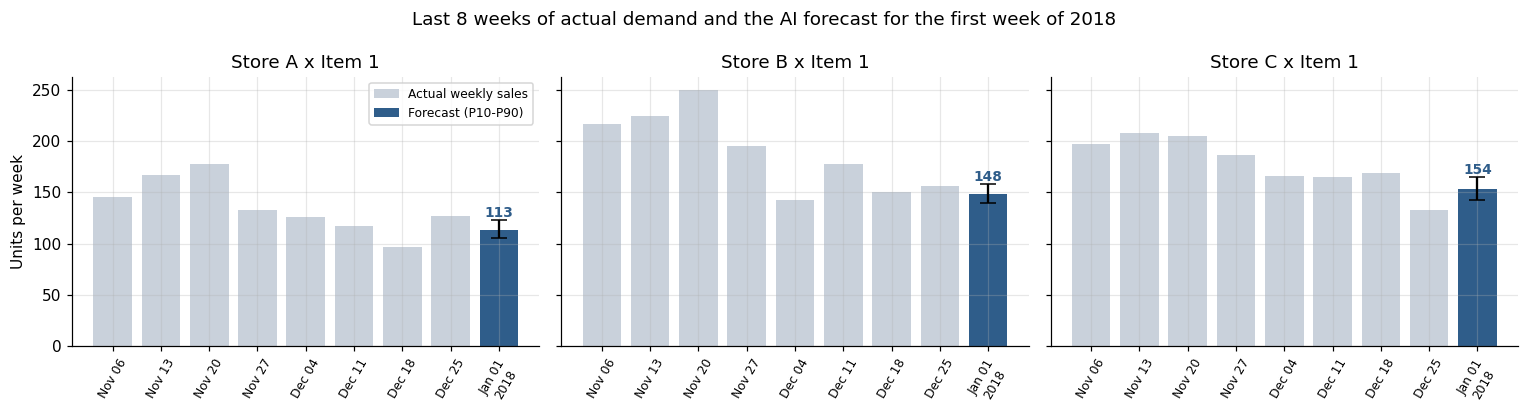

In [60]:
weeks = pd.date_range("2017-11-06", "2017-12-25", freq="7D")       # Mondays of the last 8 full weeks
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (s, name) in zip(axes, STORE_NAME.items()):
    hist = raw[(raw["store"] == s) & (raw["item"] == DEMO_ITEM)].set_index("date")["sales"]
    weekly = [hist[w: w + pd.Timedelta(days=6)].sum() for w in weeks]
    row = demo[demo["store"] == s].iloc[0]
    x_labels = [w.strftime("%b %d") for w in weeks] + ["Jan 01\n2018"]
    ax.bar(range(8), weekly, color="#c9d1db", label="Actual weekly sales")
    ax.bar(8, row["predicted_7d_demand"], color="#2f5d8a", label="Forecast (P10-P90)",
           yerr=[[row["predicted_7d_demand"] - row["range_low_P10"]],
                 [row["range_high_P90"] - row["predicted_7d_demand"]]], capsize=5)
    ax.text(8, row["range_high_P90"] + 3, f"{row['predicted_7d_demand']:.0f}", ha="center", fontsize=9,
            color="#2f5d8a", fontweight="bold")
    ax.set_xticks(range(9)); ax.set_xticklabels(x_labels, rotation=60, fontsize=8)
    ax.set_title(f"Store {name} x Item {DEMO_ITEM}")
axes[0].set_ylabel("Units per week")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Last 8 weeks of actual demand and the AI forecast for the first week of 2018", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "final_1_forecast_2018_week1.png", dpi=150, bbox_inches="tight")
plt.show()

## 9.11 保存最终预测

这段代码会保存：
- `outputs/forecast_2018-01-01.csv`：全部 500 个“门店 × 商品”组合的预测表。CSV 可以用 Excel 打开，方便组员直接查看，也是下一步 ReturnRoute 调拨规则的输入；
- `outputs/final_model_card.json`：最终模型的“说明卡”，包括训练数据范围、参数、特征、2017 年测试成绩和彩排结果，方便写 PPT 和回答问题时查阅。

In [61]:
forecast.round(1).to_csv(OUT_DIR / "forecast_2018-01-01.csv", index=False)

card = {
    "model": "RandomForestRegressor",
    "params": PARAMS,
    "features": FEATURES,
    "target": "Total sales of the next 7 days (d ... d+6)",
    "trained_on": {"rows": int(len(final_train)),
                   "first_forecast_date": str(final_train["date"].min().date()),
                   "last_forecast_date": str(final_train["date"].max().date())},
    "test_2017_performance": compare.round(3).to_dict(orient="index"),
    "rehearsal_2017_week1": {"rf_mae": round(float(mae_rf), 2), "last_week_mae": round(float(mae_lw), 2)},
    "forecast_window": f"{FORECAST_DAY.date()} to {(FORECAST_DAY + pd.Timedelta(days=6)).date()}",
}
with open(OUT_DIR / "final_model_card.json", "w") as f:
    json.dump(card, f, indent=2)
print("Saved outputs/forecast_2018-01-01.csv and outputs/final_model_card.json")

Saved outputs/forecast_2018-01-01.csv and outputs/final_model_card.json


---
# 第十阶段：AI 模型到这里就结束了

**这一点一定要分清楚。** 到这里：

```
Random Forest  →  Predicted Demand
```

AI 模型的工作就已经完成了。它只回答一个问题：**“每家店、每个商品，未来 7 天大概会卖多少？”**

ReturnRoute 后面的步骤**不是 AI**，而是根据预测结果做决策的**系统规则**和**员工**：

```
 ┌───────────────────── AI（本项目已完成） ─────────────────────┐
 │  历史销量 → 特征工程 → Random Forest → 每家店的预测需求 + 范围   │
 └──────────────────────────────┬───────────────────────────────┘
                                ↓
 ┌──────────────────────── 系统规则（不是 AI） ──────────────────────┐
 │  预测需求 − （现有库存 + 在途库存）= 缺口                           │
 │  再扣掉调拨运费、运输时间、门店容量 → 给可选去向排序                 │
 └──────────────────────────────┬───────────────────────────────┘
                                ↓
 ┌──────────────────────────── 员工 ───────────────────────────────┐
 │  查看推荐卡片和依据 → 确认 / 修改 / 拒绝调拨 → 系统记录结果          │
 └─────────────────────────────────────────────────────────────────┘
```

Presentation 里把这三层分开讲，老师问“AI 具体做什么”时就能回答得很清楚：**AI 负责预测需求；系统规则负责比较库存和成本；员工做最终决定。**

## 第九阶段的结果

| 项目 | 结果 |
|---|---|
| 最终训练数据 | **896,000 行**，预测日期 d 从 2013-01-29 到 2017-12-25，用到了 2013–2017 的每一天，是之前训练集的 1.69 倍 |
| 最终参数 | 100 棵树，`min_samples_leaf=20`，`max_features=0.5`，15 个基础特征 |
| 测试 ①：特征一致性 | 通过：711,000 行的特征与第二阶段完全一致 |
| 测试 ②：流程彩排（预测 2017 年第一周） | Random Forest MAE **17.3**，Last Week MAE 23.0，**低 25%** |
| 测试 ③：2018 年预测的合理性 | 4 项检查全部通过：预测 ÷ 上一周 = 0.985，预测 ÷ 去年第一周 = 1.093，都在 2014–2017 年的历史范围内；门店规模排序和历史一致 |
| 最终输出 | 500 个“门店 × 商品”组合在 **2018-01-01 到 01-07** 的需求预测，附 P10–P90 范围 |

**演示用的预测表（Item 1）：**

| Store | Predicted 7-day demand | Range (P10–P90) | Last week actual |
|---|---:|---:|---:|
| A | 113 | 106–123 | 127 |
| B | 148 | 139–158 | 156 |
| C | 154 | 142–165 | 133 |

可以注意到：**Store C 上周只卖了 133 件，但模型预测下周会卖 154 件**，比 A、B 两家店都高；Store A、B 的预测则低于上周。这正是 ReturnRoute 想说明的：**只看上周销量，会低估 C 店的需求**。下一步的调拨规则会把这个预测和各店的库存对比，判断退货应该送去哪里。

**需要如实说明的局限：**
- 数据集里没有 2018 年的销量，所以 2018 年的预测**无法计算误差**。模型的准确度来自 2017 年的测试结果（MAE 18.5，比 Last Week 低 31%）和上面的彩排。
- 模型只能预测“下一个 7 天”。要预测更往后的时间，需要每天拿到新的销量后重新预测，这也是真实系统的工作方式。